# Week-42

Para la reunión del jueves, yo llevaría estos dos papers. Atacan dos limitaciones diferentes y permiten construir una historia científica coherente alrededor de un “Ecological Directed SEAL”.

## 1. Dir-GNN: introducir dirección dentro del message passing

**Paper:** [Edge Directionality Improves Learning on Heterophilic Graphs](https://proceedings.mlr.press/v231/rossi24a/rossi24a.pdf) — Rossi et al., LoG 2023.  
**Código:** [directed-graph-neural-network](https://github.com/emalgorithm/directed-graph-neural-network)

Dir-GNN mantiene separados los mensajes recibidos por enlaces entrantes y salientes, en lugar de convertir la red dirigida en no dirigida.

Esto encaja directamente con nuestra principal limitación actual: SEAL-directed conserva la dirección para los candidatos, etiquetas y muestreo negativo, pero el DGCNN opera sobre la proyección débil:

\[
A_{\mathrm{weak}} = A + A^\top
\]

Por tanto, durante el message passing deja de distinguir el flujo recurso → consumidor.

### Propuesta para nuestro modelo

Crear **Dir-SEAL**:

\[
h_i^{(l+1)}
=
\phi\left(
W_{\mathrm{self}}h_i,
W_{\mathrm{in}}\operatorname{AGG}_{j\rightarrow i}(h_j),
W_{\mathrm{out}}\operatorname{AGG}_{i\rightarrow j}(h_j)
\right)
\]

Ablación propuesta:

1. SEAL original no dirigido.
2. Nuestro SEAL-directed actual.
3. SEAL con message passing únicamente entrante.
4. SEAL con message passing únicamente saliente.
5. Dir-SEAL con ambas direcciones separadas.

La hipótesis ecológica sería que consumidores y recursos desempeñan funciones asimétricas, por lo que los patrones entrantes y salientes no deberían agregarse como si fueran equivalentes.

**Importante:** el paper estudia principalmente clasificación de nodos, no link prediction. Aplicarlo dentro de los subgrafos de SEAL sería una extensión metodológica que debemos presentar como hipótesis, no como mejora garantizada.

## 2. Neo-GNN: combinar SEAL con una rama estructural interpretable

**Paper:** [Neo-GNNs: Neighborhood Overlap-aware Graph Neural Networks for Link Prediction](https://papers.nips.cc/paper/2021/hash/71ddb91e8fa0541e426a54e538075a5a-Abstract.html) — Yun et al., NeurIPS 2021.  
**Código:** [Neo-GNNs](https://github.com/seongjunyun/neo-gnns)

Neo-GNN parte de una observación relevante: en link prediction, heurísticas estructurales simples pueden superar a una GNN porque la GNN puede depender demasiado de los atributos y no explotar suficientemente la estructura.

Su solución combina:

- Una representación aprendida mediante GNN.
- Una rama estructural basada en solapamiento de vecindarios multi-hop.
- Una combinación aprendida entre ambas predicciones.

### Propuesta para nuestro modelo

Crear **Eco-Neo-SEAL**, manteniendo el score de SEAL y añadiendo una rama estructural dirigida:

- Predecesores comunes.
- Sucesores comunes.
- Caminos dirigidos recurso → intermediario → consumidor.
- Grados de entrada y salida.
- Posición trófica y compatibilidad de roles.

Por ejemplo:

\[
s(u,v)
=
\alpha\,s_{\mathrm{SEAL}}(u,v)
+
(1-\alpha)\,s_{\mathrm{struct}}(u,v)
\]

Esto nos permitiría determinar:

- Cuánto aporta la estructura frente a los 44 atributos.
- Qué patrones ecológicos explican una predicción.
- Si el modelo generaliza cuando los atributos son incompletos.
- Si las heurísticas dirigidas mejoran especialmente PR-AUC, Recall, MCC o TSS.

La adaptación debe calcularse únicamente sobre la red de entrenamiento y retirando el enlace candidato; de lo contrario habría leakage.

## Mi recomendación

La propuesta principal debería ser **Dir-SEAL**, porque corrige una limitación concreta de nuestra implementación y tiene una justificación ecológica fuerte.

Neo-GNN sería la segunda vía: una variante híbrida más interpretable, que podría convertirse tanto en una mejora como en una ablación para demostrar de dónde procede la capacidad predictiva.

Una formulación breve para tu supervisora sería:

> I propose to develop a genuinely direction-aware SEAL architecture by separating incoming and outgoing message passing within each enclosing subgraph. In parallel, we could test a Neo-GNN-inspired structural branch based on directed neighborhood overlap and trophic paths. This would let us assess whether predictive performance comes primarily from node attributes, local subgraph representations or ecologically meaningful directed motifs.

## ¿Qué es `SEAL_OGB`?

[SEAL_OGB](https://github.com/facebookresearch/SEAL_OGB#usages) es una reimplementación de SEAL en PyTorch Geometric para los benchmarks de link prediction de OGB.

En pocas palabras, hace lo siguiente:

```text
Enlace candidato
      ↓
Subgrafo envolvente de k saltos
      ↓
Etiquetado de nodos relativo a los dos extremos
      ↓
GNN que clasifica el subgrafo
      ↓
Probabilidad de que exista el enlace
```

Por defecto emplea DRNL para etiquetar los nodos y DGCNN para clasificar el subgrafo, pero permite probar:

- DGCNN, GCN, GraphSAGE y GIN.
- DRNL, Distance Encoding, DE+ y Zero-One labeling.
- Atributos de nodos y pesos de enlaces.
- Diferentes números de saltos.
- Extracción dinámica de subgrafos.
- Common Neighbors y Adamic–Adar como baselines.

Los comandos de “Usages” son recetas específicas para cada dataset OGB, no configuraciones universalmente óptimas.

Para nuestro proyecto, sus ideas más aprovechables son:

1. Comparar `DRNL`, `DE`, `DE+` y `ZO`.
2. Comparar DGCNN contra GIN, GraphSAGE y GCN.
3. Incorporar extracción dinámica para reducir almacenamiento.
4. Incluir heurísticas estructurales como baselines.
5. Modernizar el pipeline sobre PyTorch Geometric.

Sin embargo, no usaría directamente ese repositorio como base de producción: fue archivado en julio de 2025 y sus combinaciones probadas de Python, PyTorch y PyG son antiguas. Además, no resuelve por sí solo la dirección ecológica; habría que adaptar extracción, etiquetado y message passing. [Repositorio y documentación](https://github.com/facebookresearch/SEAL_OGB).


[INFO] Panel a: Bridge brook lake


/var/folders/fh/0vq0142d1t36s502_bgq3z480000gp/T/ipykernel_11216/3107914629.py:792: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
        That means the default return type will be a sparse array.
        Unless you use * instead of @, ** for matrix power, or you depend
        on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
        See the spmatrix to sparray migration guide for details.
        https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
        
  data = scipy.io.loadmat(


[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=90%, ExperimentID=1, threshold=0.50
  Seed=426802189
  Train=493, TP=55, FP=0, FN=0
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs/Bridge brook lake_tax_mass_results_random_wlnm_dir_neg.csv
  Snapshot=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/ecological_snapshots/Bridge_brook_lake_tax_mass_K10_ratio0.9_exp1_seed426802189_threshold0.5_validated_v2.mat

[INFO] Panel b: Bridge brook lake
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=60%, ExperimentID=1, threshold=0.50
  Seed=424050289
  Train=328, TP=218, FP=4, FN=2
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_1

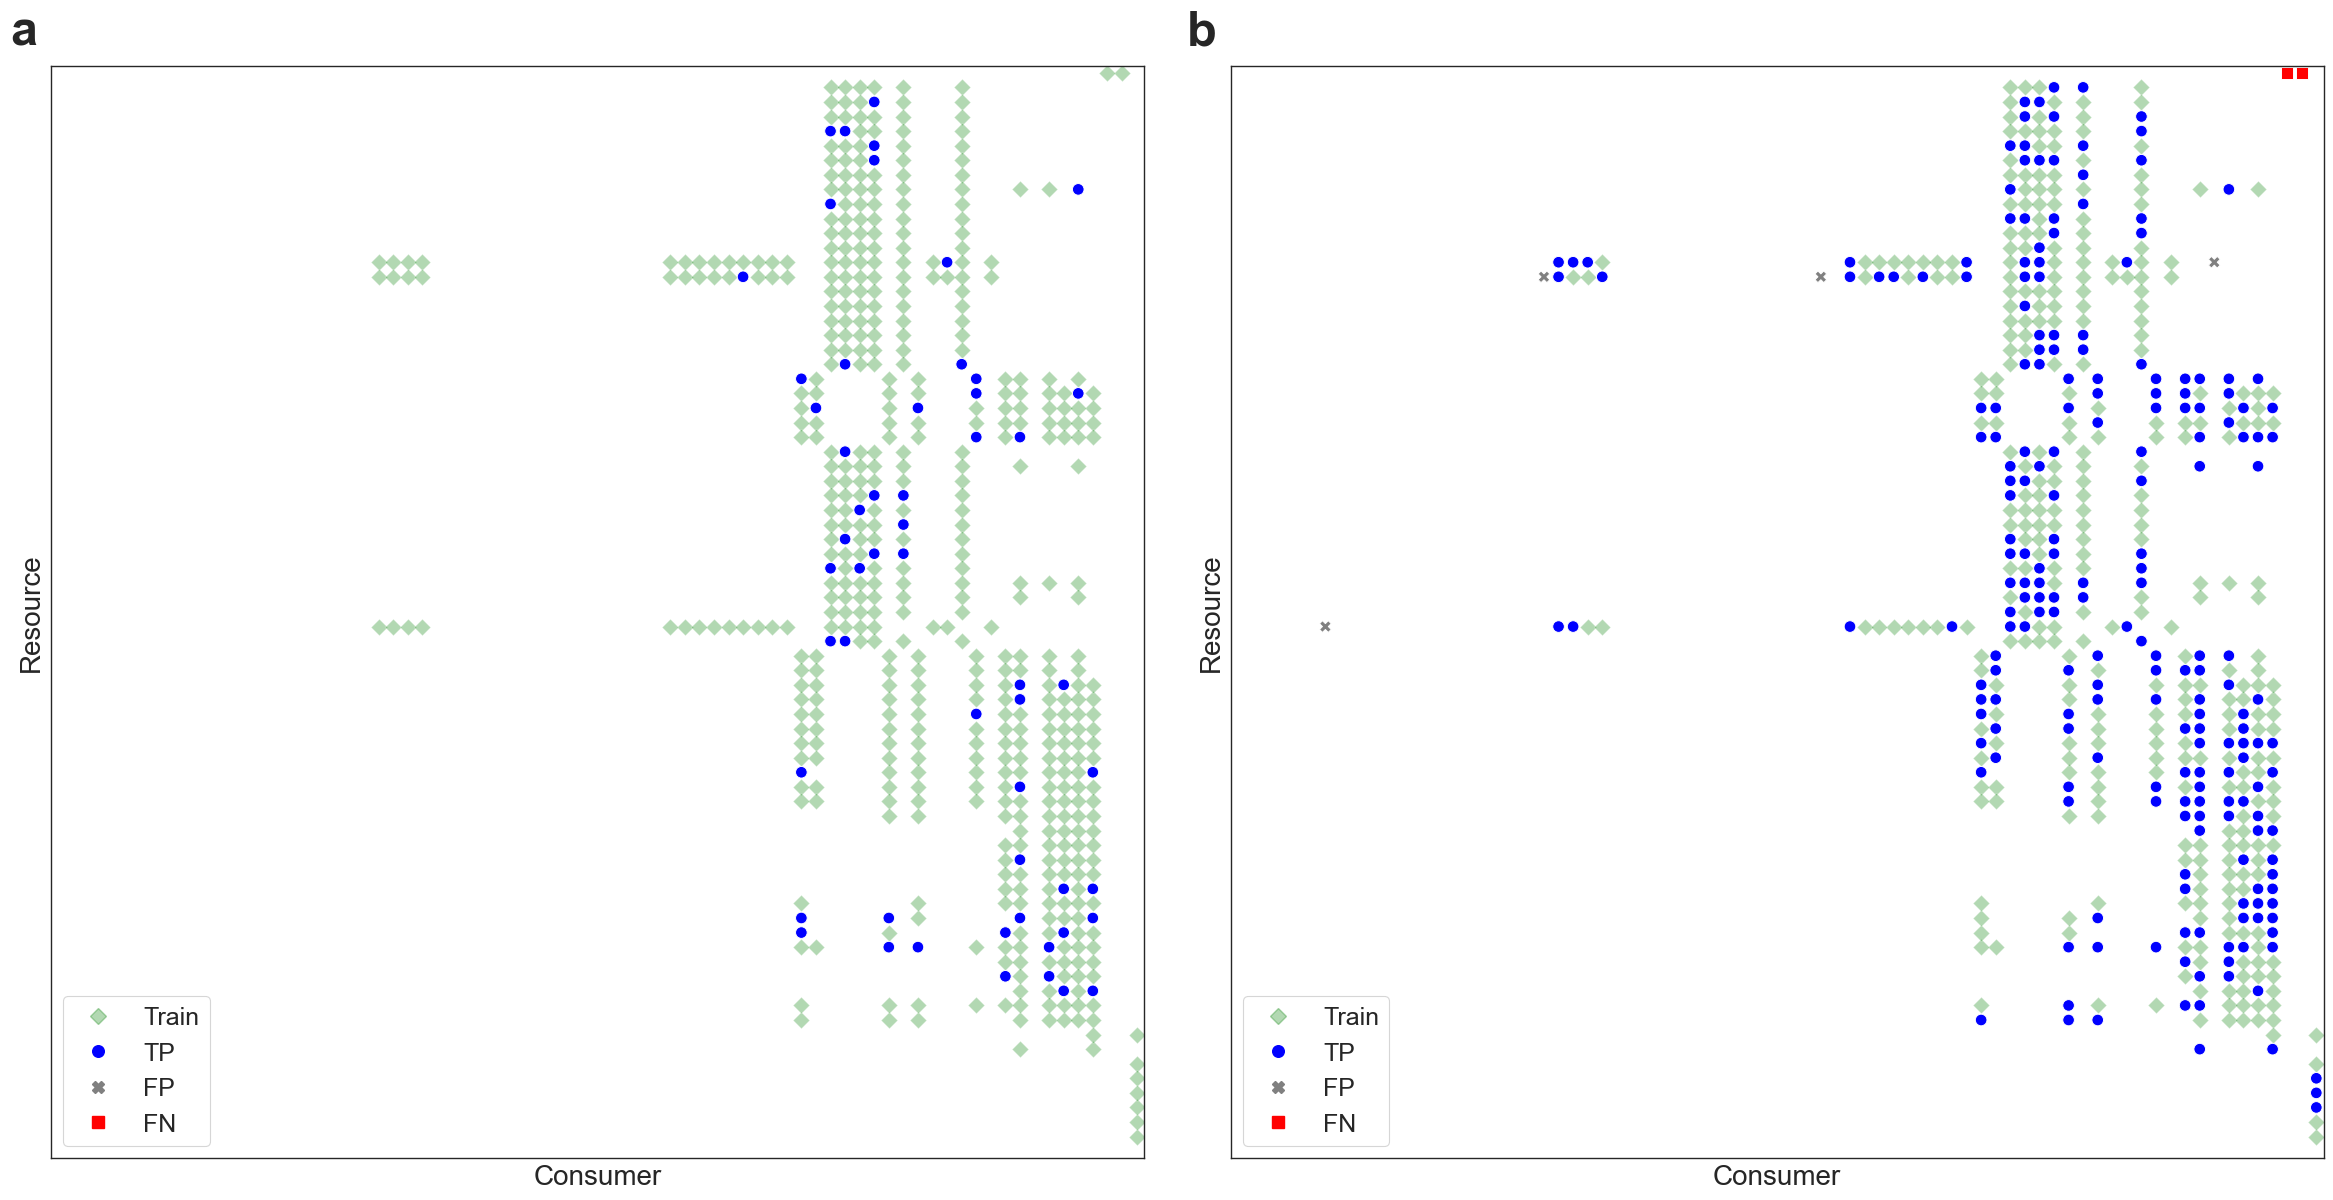

In [2]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.sparse import csr_matrix, issparse


# ============================================================
# Style + repository
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=3)


def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    for candidate in [start, *start.parents]:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        f"Could not locate repository root from {start}"
    )


REPO_ROOT = find_repo_root()


# ============================================================
# SIMPLE PANEL CONFIGURATION
# Edit foodweb, train_ratio and experiment_id per panel.
# train_ratio accepts 60 / 90 or 0.60 / 0.90.
# ============================================================

DEFAULT_FOODWEB = "Bridge brook lake"

PANELS = [
    {
        "letter": "a",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 90,
        "experiment_id": 1,
    },
    {
        "letter": "b",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 60,
        "experiment_id": 1,
    },
]

K_TARGET = 10
CLASSIFICATION_THRESHOLD = 0.50


# ============================================================
# Existing figure controls
# ============================================================

MIN_NODES = 40

SHOW_TITLES = False
SHOW_TICKS = False
USE_NUMERIC_AXIS_LABELS = False

XLAB = "Consumer"
YLAB = "Resource"

PANEL_XTICK_FONTSIZES = [12, 12]
PANEL_YTICK_FONTSIZES = [12, 12]

PRINT_SPECIES_KEY = False
EXPORT_SPECIES_KEY_FILE = True
SPECIES_KEY_FORMAT = "csv"

SPECIES_KEY_DIR = (
    REPO_ROOT
    / "docs/progress_notebooks_logs/2026/species_keys"
)


# ============================================================
# Input paths
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

PREDICTION_LOG_DIR = (
    RESULT_ROOT
    / "prediction_scores_logs"
)

ECOLOGICAL_SNAPSHOTS_DIR = (
    RESULT_ROOT
    / "ecological_snapshots"
)

BASE_MAT_PATH = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
)


# ============================================================
# Initial references
# Used only for the untouched initial configuration.
# Seeds are always read from the selected CSV row.
# ============================================================

def canonical_foodweb(name):
    name = str(name).strip()

    return (
        name[:-len("_tax_mass")]
        if name.endswith("_tax_mass")
        else name
    )


REFERENCE_FOODWEB = (
    "Grand Caricaie  marsh dominated by "
    "Cladietum marisci, not mown  ClControl2"
)


INITIAL_REFERENCE = {
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        60.0,
        21,
    ): {
        "seed": 1314098572,
        "TrainLinks": 460,
        "TestTP": 284,
        "TestFP": 8,
        "TestFN": 24,
    },
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        90.0,
        21,
    ): {
        "seed": 1316850472,
        "TrainLinks": 691,
        "TestTP": 39,
        "TestFP": 0,
        "TestFN": 38,
    },
}


# ============================================================
# Helpers
# ============================================================

def norm_name(value):
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def find_col(
    df,
    *aliases,
    required=True,
):
    lookup = {
        norm_name(column): column
        for column in df.columns
    }

    for alias in aliases:
        key = norm_name(alias)

        if key in lookup:
            return lookup[key]

    if required:
        raise KeyError(
            f"Missing required column. Tried {aliases}. "
            f"Available columns: {list(df.columns)}"
        )

    return None


def ratio_percent(value):
    value = float(value)

    if 0 < value <= 1:
        value *= 100

    if not 0 < value <= 100:
        raise ValueError(
            f"Invalid train_ratio={value!r}"
        )

    return float(value)


def tax_mass_stem(foodweb):
    foodweb = str(foodweb).strip()

    return (
        foodweb
        if foodweb.endswith("_tax_mass")
        else f"{foodweb}_tax_mass"
    )


def as_int(
    value,
    label,
):
    numeric = pd.to_numeric(
        pd.Series([value]),
        errors="coerce",
    ).iloc[0]

    if pd.isna(numeric):
        raise ValueError(
            f"{label} is not numeric: {value!r}"
        )

    integer = int(
        round(
            float(numeric)
        )
    )

    if not np.isclose(
        float(numeric),
        integer,
        atol=1e-9,
        rtol=0,
    ):
        raise ValueError(
            f"{label} is not an integer: {value!r}"
        )

    return integer


def binary_csr(matrix):
    if issparse(matrix):
        out = matrix.tocsr(
            copy=True
        )
    else:
        out = csr_matrix(
            np.asarray(matrix)
        )

    out.sum_duplicates()
    out.eliminate_zeros()

    if out.nnz:
        out.data = np.ones(
            out.nnz,
            dtype=np.int8,
        )

    return out.astype(
        np.int8
    )


def mask_and(
    a,
    b,
):
    out = a.multiply(
        b
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        out.data[:] = 1

    return out


def mask_and_not(
    a,
    b,
):
    out = (
        a.astype(np.int8)
        - a.multiply(b).astype(np.int8)
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        if np.any(
            out.data < 0
        ):
            raise ValueError(
                "Unexpected negative entries while "
                "reconstructing sparse masks."
            )

        out.data[:] = 1

    return out


def sparse_equal(
    a,
    b,
):
    if a.shape != b.shape:
        return False

    diff = (
        a.astype(np.int8)
        - b.astype(np.int8)
    ).tocsr()

    diff.eliminate_zeros()

    return (
        diff.nnz == 0
    )


def unwrap(value):
    while (
        isinstance(
            value,
            np.ndarray,
        )
        and value.size == 1
    ):
        value = value.reshape(
            -1
        )[0]

    return value


def matlab_str(value):
    value = unwrap(
        value
    )

    if isinstance(
        value,
        (bytes, np.bytes_),
    ):
        return bytes(
            value
        ).decode(
            "utf-8",
            errors="replace",
        ).strip()

    if isinstance(
        value,
        str,
    ):
        return value.strip()

    if isinstance(
        value,
        np.str_,
    ):
        return str(
            value
        ).strip()

    if (
        isinstance(
            value,
            np.ndarray,
        )
        and value.dtype.kind
        in {
            "U",
            "S",
        }
    ):
        parts = []

        for item in value.reshape(
            -1
        ):
            if isinstance(
                item,
                (bytes, np.bytes_),
            ):
                parts.append(
                    bytes(
                        item
                    ).decode(
                        "utf-8",
                        errors="replace",
                    )
                )

            else:
                parts.append(
                    str(
                        item
                    )
                )

        return "".join(
            parts
        ).strip()

    return str(
        value
    ).strip()


def matlab_str_list(value):
    return [
        matlab_str(
            item
        )
        for item
        in np.asarray(
            value,
            dtype=object,
        ).reshape(-1)
    ]


def struct_fields(obj):
    obj = unwrap(
        obj
    )

    if isinstance(
        obj,
        dict,
    ):
        return list(
            obj.items()
        )

    names = getattr(
        obj,
        "_fieldnames",
        None,
    )

    if names:
        return [
            (
                name,
                getattr(
                    obj,
                    name,
                ),
            )
            for name in names
        ]

    if (
        isinstance(
            obj,
            np.void,
        )
        and obj.dtype.names
    ):
        return [
            (
                name,
                obj[name],
            )
            for name
            in obj.dtype.names
        ]

    return []


def struct_get(
    obj,
    field,
):
    target = norm_name(
        field
    )

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) == target:
            return value

    raise KeyError(
        f"MATLAB struct is missing field "
        f"{field!r}. "
        f"Available fields: "
        f"{[name for name, _ in struct_fields(obj)]}"
    )


def struct_get_optional(
    obj,
    *aliases,
):
    targets = {
        norm_name(alias)
        for alias in aliases
    }

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) in targets:
            return value

    return None


# ============================================================
# Exact CSV row selection
# ============================================================

def select_run(panel):
    foodweb = panel[
        "foodweb"
    ]

    ratio = ratio_percent(
        panel[
            "train_ratio"
        ]
    )

    experiment_id = int(
        panel[
            "experiment_id"
        ]
    )

    csv_path = (
        PREDICTION_LOG_DIR
        / (
            f"{tax_mass_stem(foodweb)}"
            "_results_random_wlnm_dir_neg.csv"
        )
    )

    if not csv_path.is_file():
        raise FileNotFoundError(
            "Results CSV not found:\n"
            f"  {csv_path}"
        )

    df = pd.read_csv(
        csv_path
    )

    k_col = find_col(
        df,
        "K",
        "SubgraphK",
    )

    ratio_col = find_col(
        df,
        "TrainRatio",
        "TrainingRatio",
    )

    exp_col = find_col(
        df,
        "ExperimentID",
        "Experiment",
    )

    threshold_col = find_col(
        df,
        "Threshold",
        "ClassificationThreshold",
    )

    foodweb_col = find_col(
        df,
        "Foodweb",
        "FoodWebName",
        required=False,
    )

    k = pd.to_numeric(
        df[k_col],
        errors="coerce",
    )

    train_ratio = pd.to_numeric(
        df[ratio_col],
        errors="coerce",
    )

    train_ratio = np.where(
        train_ratio
        <= 1.0 + 1e-12,
        train_ratio * 100.0,
        train_ratio,
    )

    experiment = pd.to_numeric(
        df[exp_col],
        errors="coerce",
    )

    threshold = pd.to_numeric(
        df[threshold_col],
        errors="coerce",
    )

    mask = (
        np.isclose(
            k,
            K_TARGET,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            train_ratio,
            ratio,
            atol=1e-9,
            rtol=0,
        )
        & np.isclose(
            experiment,
            experiment_id,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            threshold,
            CLASSIFICATION_THRESHOLD,
            atol=1e-12,
            rtol=0,
        )
    )

    if (
        foodweb_col
        is not None
    ):
        mask &= (
            df[foodweb_col]
            .astype(str)
            .map(
                canonical_foodweb
            )
            .eq(
                canonical_foodweb(
                    foodweb
                )
            )
        )

    matches = df.loc[
        mask
    ]

    if len(
        matches
    ) != 1:
        raise ValueError(
            "Expected exactly one matching run, "
            f"but found {len(matches)}.\n"
            f"  foodweb={foodweb!r}\n"
            f"  K={K_TARGET}\n"
            f"  TrainRatio={ratio:g}%\n"
            f"  ExperimentID={experiment_id}\n"
            f"  threshold={CLASSIFICATION_THRESHOLD}\n"
            f"  CSV={csv_path}"
        )

    return (
        matches.iloc[0],
        csv_path,
        ratio,
    )


# ============================================================
# Resolve LOCAL snapshot by basename only
# ============================================================

def local_snapshot_from_row(row):
    row_df = pd.DataFrame(
        [row]
    )

    snapshot_col = find_col(
        row_df,
        "TrophicSnapshotFile",
        "SnapshotFile",
    )

    raw = row[
        snapshot_col
    ]

    if pd.isna(
        raw
    ):
        raise ValueError(
            "TrophicSnapshotFile is empty "
            "for the selected run."
        )

    snapshot_name = (
        str(raw)
        .strip()
        .replace(
            "\\",
            "/",
        )
        .split("/")[-1]
    )

    matches = [
        path
        for path
        in ECOLOGICAL_SNAPSHOTS_DIR.rglob(
            "*.mat"
        )
        if path.name
        == snapshot_name
    ]

    if len(
        matches
    ) != 1:
        raise FileNotFoundError(
            "Expected exactly one LOCAL "
            "ecological snapshot, "
            f"found {len(matches)}.\n"
            f"  basename={snapshot_name!r}\n"
            f"  searched under="
            f"{ECOLOGICAL_SNAPSHOTS_DIR}\n"
            f"  matches={matches}"
        )

    return matches[0]


# ============================================================
# Load tax/mass file
# ============================================================

def load_tax_mass(foodweb):
    mat_path = (
        BASE_MAT_PATH
        / (
            f"{tax_mass_stem(foodweb)}"
            ".mat"
        )
    )

    if not mat_path.is_file():
        raise FileNotFoundError(
            "Food-web tax/mass MAT "
            "not found:\n"
            f"  {mat_path}"
        )

    data = scipy.io.loadmat(
        mat_path,
        struct_as_record=False,
        squeeze_me=True,
    )

    for key in (
        "net",
        "taxonomy",
        "mass",
    ):
        if key not in data:
            raise KeyError(
                f"{mat_path} "
                f"is missing {key!r}"
            )

    net = binary_csr(
        data[
            "net"
        ]
    )
    # WLNM_dir_neg removes self-loops before saving empirical.
    net.setdiag(0)
    net.eliminate_zeros()

    taxonomy = matlab_str_list(
        data[
            "taxonomy"
        ]
    )

    mass = np.asarray(
        data[
            "mass"
        ]
    ).reshape(
        -1
    ).astype(
        float
    )

    n = len(
        taxonomy
    )

    if len(
        mass
    ) != n:
        raise ValueError(
            "taxonomy and mass "
            "have different lengths in "
            f"{mat_path}"
        )

    if net.shape != (
        n,
        n,
    ):
        raise ValueError(
            f"net.shape={net.shape}, "
            f"expected {(n, n)}"
        )

    if n < MIN_NODES:
        raise ValueError(
            f"Selected food web has "
            f"{n} nodes, below "
            f"MIN_NODES={MIN_NODES}."
        )

    if not np.all(
        np.isfinite(
            mass
        )
    ):
        raise ValueError(
            "Non-finite body masses "
            f"found in {mat_path}"
        )

    normalized = [
        re.sub(
            r"\s+",
            " ",
            value.strip(),
        )
        for value
        in taxonomy
    ]

    if len(
        set(
            normalized
        )
    ) != n:
        raise ValueError(
            "Duplicate taxonomy labels "
            "found; node mapping is ambiguous."
        )

    return (
        mat_path,
        net,
        taxonomy,
        mass,
    )


# ============================================================
# Load snapshot + reconstruct Train / TP / FP / FN
# ============================================================

def load_snapshot(
    snapshot_path,
    base_net,
    taxonomy,
):
    data = scipy.io.loadmat(
        snapshot_path,
        struct_as_record=False,
        squeeze_me=True,
    )

    if (
        "snapshot"
        not in data
    ):
        raise KeyError(
            "'snapshot' struct "
            "not found in "
            f"{snapshot_path}"
        )

    snapshot = data[
        "snapshot"
    ]

    empirical = binary_csr(
        struct_get(
            snapshot,
            "empirical",
        )
    )

    train = binary_csr(
        struct_get(
            snapshot,
            "train",
        )
    )

    pseudo = binary_csr(
        struct_get(
            snapshot,
            "pseudo",
        )
    )

    metadata = struct_get(
        snapshot,
        "metadata",
    )

    n = len(
        taxonomy
    )

    for name, matrix in {
        "empirical": empirical,
        "train": train,
        "pseudo": pseudo,
    }.items():

        if matrix.shape != (
            n,
            n,
        ):
            raise ValueError(
                f"snapshot.{name}.shape="
                f"{matrix.shape}, "
                f"expected {(n, n)}"
            )

    # Validate snapshot node indexing and direction against
    # the original directed food-web matrix.
    if not sparse_equal(
        empirical,
        base_net,
    ):
        if sparse_equal(
            empirical,
            base_net.T.tocsr(),
        ):
            raise ValueError(
                "snapshot.empirical matches "
                "net.T rather than net. "
                "Direction/index convention "
                "is inconsistent."
            )

        raise ValueError(
            "snapshot.empirical does not "
            "match the tax_mass net. "
            "Node identity/order cannot "
            "be validated safely."
        )

    train_outside_empirical = (
        mask_and_not(
            train,
            empirical,
        )
    )

    if (
        train_outside_empirical.nnz
    ):
        raise ValueError(
            "snapshot.train contains "
            f"{train_outside_empirical.nnz} "
            "links absent from empirical."
        )

    # If metadata exposes node names, verify those explicitly too.
    metadata_nodes = struct_get_optional(
        metadata,
        "taxonomy",
        "taxa",
        "species",
        "species_names",
        "node_names",
        "node_labels",
    )

    if (
        metadata_nodes
        is not None
    ):
        names = matlab_str_list(
            metadata_nodes
        )

        if len(
            names
        ) == n:

            def clean(value):
                return re.sub(
                    r"\s+",
                    " ",
                    value.strip(),
                )

            if (
                list(
                    map(
                        clean,
                        names,
                    )
                )
                != list(
                    map(
                        clean,
                        taxonomy,
                    )
                )
            ):
                raise ValueError(
                    "Snapshot metadata node names "
                    "do not match tax_mass taxonomy "
                    "in the same index order."
                )

            print(
                "[INFO] Snapshot node names "
                "match tax_mass taxonomy."
            )

    # --------------------------------------------------------
    # Required reconstruction
    # --------------------------------------------------------
    #
    # Train          = train
    # true_test      = empirical & ~train
    # predicted_test = pseudo & ~train
    # TP             = true_test & predicted_test
    # FP             = predicted_test & ~true_test
    # FN             = true_test & ~predicted_test
    #

    true_test = mask_and_not(
        empirical,
        train,
    )

    predicted_test = mask_and_not(
        pseudo,
        train,
    )

    tp = mask_and(
        true_test,
        predicted_test,
    )

    fp = mask_and_not(
        predicted_test,
        true_test,
    )

    fn = mask_and_not(
        true_test,
        predicted_test,
    )

    return {
        "Train": train,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "metadata": metadata,
    }


# ============================================================
# Validate seed + reconstructed counts against selected CSV row
# ============================================================

def validate_run(
    row,
    panel,
    ratio,
    masks,
    snapshot_path,
):
    row_df = pd.DataFrame(
        [row]
    )

    seed_col = find_col(
        row_df,
        "Seed",
        "RandomSeed",
        "ExperimentSeed",
    )

    train_col = find_col(
        row_df,
        "TrainLinks",
    )

    tp_col = find_col(
        row_df,
        "TestTP",
    )

    fp_col = find_col(
        row_df,
        "TestFP",
    )

    fn_col = find_col(
        row_df,
        "TestFN",
    )

    seed = as_int(
        row[
            seed_col
        ],
        "Seed",
    )

    csv_counts = {
        "TrainLinks": as_int(
            row[
                train_col
            ],
            "TrainLinks",
        ),
        "TestTP": as_int(
            row[
                tp_col
            ],
            "TestTP",
        ),
        "TestFP": as_int(
            row[
                fp_col
            ],
            "TestFP",
        ),
        "TestFN": as_int(
            row[
                fn_col
            ],
            "TestFN",
        ),
    }

    reconstructed = {
        "TrainLinks": (
            masks[
                "Train"
            ].nnz
        ),
        "TestTP": (
            masks[
                "TP"
            ].nnz
        ),
        "TestFP": (
            masks[
                "FP"
            ].nnz
        ),
        "TestFN": (
            masks[
                "FN"
            ].nnz
        ),
    }

    if (
        csv_counts
        != reconstructed
    ):
        raise ValueError(
            "Reconstructed counts do not "
            "match the selected CSV row.\n"
            f"  CSV={csv_counts}\n"
            f"  reconstructed={reconstructed}\n"
            f"  snapshot={snapshot_path}"
        )

    # If metadata contains its own seed, verify that too.
    metadata_seed = struct_get_optional(
        masks[
            "metadata"
        ],
        "seed",
        "random_seed",
        "experiment_seed",
    )

    if (
        metadata_seed
        is not None
    ):
        snapshot_seed = as_int(
            unwrap(
                metadata_seed
            ),
            "snapshot metadata seed",
        )

        if (
            snapshot_seed
            != seed
        ):
            raise ValueError(
                "Seed mismatch between CSV "
                "and snapshot metadata:\n"
                f"  CSV={seed}\n"
                f"  snapshot={snapshot_seed}"
            )

    # Only the untouched initial configuration is checked
    # against the supplied reference seed/counts.
    ref_key = (
        canonical_foodweb(
            panel[
                "foodweb"
            ]
        ),
        float(
            ratio
        ),
        int(
            panel[
                "experiment_id"
            ]
        ),
    )

    reference = INITIAL_REFERENCE.get(
        ref_key
    )

    if (
        reference
        is not None
    ):
        if (
            seed
            != reference[
                "seed"
            ]
        ):
            raise ValueError(
                "Initial seed does not match "
                "the supplied reference:\n"
                f"  expected="
                f"{reference['seed']}\n"
                f"  CSV={seed}"
            )

        for key in (
            "TrainLinks",
            "TestTP",
            "TestFP",
            "TestFN",
        ):
            if (
                reconstructed[
                    key
                ]
                != reference[
                    key
                ]
            ):
                raise ValueError(
                    "Initial reference mismatch "
                    f"for {key}: "
                    f"expected={reference[key]}, "
                    f"observed={reconstructed[key]}"
                )

    return (
        seed,
        reconstructed,
    )


# ============================================================
# Sparse directed links -> mass-sorted plotting coordinates
#
# Matrix convention:
#   row    = Resource / Prey
#   column = Consumer / Predator
# ============================================================

def mask_to_df(
    mask,
    original_to_sorted,
    label,
):
    (
        resource_idx,
        consumer_idx,
    ) = mask.nonzero()

    return pd.DataFrame({
        "PreyIdx": (
            original_to_sorted[
                resource_idx
            ]
        ),
        "PredIdx": (
            original_to_sorted[
                consumer_idx
            ]
        ),
        "Label": label,
    })


# ============================================================
# Validate ALL panels before drawing
# ============================================================

for label, path in {
    "prediction_scores_logs":
        PREDICTION_LOG_DIR,
    "ecological_snapshots":
        ECOLOGICAL_SNAPSHOTS_DIR,
    "foodwebs_mat":
        BASE_MAT_PATH,
}.items():

    if not path.is_dir():
        raise FileNotFoundError(
            f"Missing {label} directory:\n"
            f"  {path}"
        )


prepared = []
tax_mass_cache = {}
species_key_done = set()


for panel_idx, panel in enumerate(
    PANELS
):
    letter = panel.get(
        "letter",
        chr(
            ord("a")
            + panel_idx
        ),
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"[INFO] Panel {letter}: "
        f"{canonical_foodweb(panel['foodweb'])}"
    )

    # --------------------------------------------------------
    # 1. Locate exactly one run in prediction_scores_logs
    # --------------------------------------------------------

    (
        row,
        results_csv,
        ratio,
    ) = select_run(
        panel
    )

    # --------------------------------------------------------
    # 2. Resolve LOCAL snapshot from TrophicSnapshotFile basename
    # --------------------------------------------------------

    snapshot_path = (
        local_snapshot_from_row(
            row
        )
    )

    # --------------------------------------------------------
    # 3. Load taxonomy / mass / empirical net
    # --------------------------------------------------------

    stem = tax_mass_stem(
        panel[
            "foodweb"
        ]
    )

    if (
        stem
        not in tax_mass_cache
    ):
        tax_mass_cache[
            stem
        ] = load_tax_mass(
            panel[
                "foodweb"
            ]
        )

    (
        tax_mass_path,
        base_net,
        taxonomy,
        mass,
    ) = tax_mass_cache[
        stem
    ]

    # --------------------------------------------------------
    # 4. Load snapshot and reconstruct Train / TP / FP / FN
    # --------------------------------------------------------

    masks = load_snapshot(
        snapshot_path,
        base_net,
        taxonomy,
    )

    # --------------------------------------------------------
    # 5. Validate seed and reconstructed counts
    # --------------------------------------------------------

    (
        seed,
        counts,
    ) = validate_run(
        row=row,
        panel=panel,
        ratio=ratio,
        masks=masks,
        snapshot_path=snapshot_path,
    )

    print(
        "[INFO] Exact run validated:\n"
        f"  K={K_TARGET}, "
        f"TrainRatio={ratio:g}%, "
        f"ExperimentID="
        f"{panel['experiment_id']}, "
        f"threshold="
        f"{CLASSIFICATION_THRESHOLD:.2f}\n"
        f"  Seed={seed}\n"
        f"  Train="
        f"{counts['TrainLinks']:,}, "
        f"TP={counts['TestTP']:,}, "
        f"FP={counts['TestFP']:,}, "
        f"FN={counts['TestFN']:,}\n"
        f"  CSV={results_csv}\n"
        f"  Snapshot={snapshot_path}"
    )

    # --------------------------------------------------------
    # 6. Sort species by body mass
    # --------------------------------------------------------

    # Same conversion used by the original cell.
    mass_mg = np.round(
        mass * 1000.0,
        4,
    )

    sorted_original_idx = np.argsort(
        mass_mg,
        kind="stable",
    )

    sorted_species = [
        taxonomy[
            index
        ]
        for index
        in sorted_original_idx
    ]

    sorted_mass_mg = (
        mass_mg[
            sorted_original_idx
        ]
    )

    n = len(
        sorted_species
    )

    original_to_sorted = np.empty(
        n,
        dtype=int,
    )

    original_to_sorted[
        sorted_original_idx
    ] = np.arange(
        n
    )

    # Stable numbering for the same food web in both panels.
    species_to_num = {
        species: index + 1
        for index, species
        in enumerate(
            sorted_species
        )
    }

    # --------------------------------------------------------
    # Optional species key
    # --------------------------------------------------------

    if (
        PRINT_SPECIES_KEY
        and stem
        not in species_key_done
    ):
        key_df = pd.DataFrame({
            "Number": np.arange(
                1,
                n + 1,
            ),
            "Species":
                sorted_species,
            "Mass_mg":
                sorted_mass_mg,
        })

        key_df[
            "Mass_mg"
        ] = (
            key_df[
                "Mass_mg"
            ]
            .map(
                lambda value:
                f"{value:.4f}"
            )
        )

        print(
            "\n"
            + key_df.to_string(
                index=False
            )
        )

        if (
            EXPORT_SPECIES_KEY_FILE
        ):
            SPECIES_KEY_DIR.mkdir(
                parents=True,
                exist_ok=True,
            )

            safe_foodweb = re.sub(
                r"[^A-Za-z0-9._-]+",
                "_",
                stem,
            ).strip(
                "_"
            )

            extension = (
                "tsv"
                if (
                    SPECIES_KEY_FORMAT.lower()
                    == "tsv"
                )
                else "csv"
            )

            output_path = (
                SPECIES_KEY_DIR
                / (
                    f"{safe_foodweb}_"
                    f"species_key."
                    f"{extension}"
                )
            )

            key_df.to_csv(
                output_path,
                sep=(
                    "\t"
                    if extension
                    == "tsv"
                    else ","
                ),
                index=False,
                encoding="utf-8",
            )

            print(
                "[INFO] Saved species key: "
                f"{output_path.resolve()}"
            )

        species_key_done.add(
            stem
        )

    # --------------------------------------------------------
    # 7. Convert reconstructed matrices to plot coordinates
    # --------------------------------------------------------

    df_train = mask_to_df(
        masks[
            "Train"
        ],
        original_to_sorted,
        "Train",
    )

    df_pm = pd.concat(
        [
            mask_to_df(
                masks[
                    "TP"
                ],
                original_to_sorted,
                "TP",
            ),
            mask_to_df(
                masks[
                    "FP"
                ],
                original_to_sorted,
                "FP",
            ),
            mask_to_df(
                masks[
                    "FN"
                ],
                original_to_sorted,
                "FN",
            ),
        ],
        ignore_index=True,
    )

    prepared.append({
        "letter":
            letter,
        "foodweb":
            canonical_foodweb(
                panel[
                    "foodweb"
                ]
            ),
        "train_ratio":
            ratio,
        "experiment_id":
            int(
                panel[
                    "experiment_id"
                ]
            ),
        "seed":
            seed,
        "n":
            n,
        "sorted_species":
            sorted_species,
        "species_to_num":
            species_to_num,
        "df_train":
            df_train,
        "df_pm":
            df_pm,
    })


# ============================================================
# Plot only AFTER every panel has passed all checks
# ============================================================

fig, axs = plt.subplots(
    1,
    len(
        prepared
    ),
    figsize=(
        12 * len(
            prepared
        ),
        12,
    ),
    squeeze=False,
)

axs = axs.ravel()


# Keep Train / TP / FP / FN in every legend,
# including FP when FP=0 in panel b.
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="None",
        markerfacecolor="green",
        markeredgecolor="green",
        alpha=0.3,
        markersize=np.sqrt(
            70
        ),
        label="Train",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="blue",
        markeredgecolor="blue",
        markersize=np.sqrt(
            70
        ),
        label="TP",
    ),
    Line2D(
        [0],
        [0],
        marker="X",
        linestyle="None",
        markerfacecolor="gray",
        markeredgecolor="gray",
        markersize=np.sqrt(
            70
        ),
        label="FP",
    ),
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=np.sqrt(
            70
        ),
        label="FN",
    ),
]


for panel_idx, panel in enumerate(
    prepared
):
    ax = axs[
        panel_idx
    ]

    n = panel[
        "n"
    ]

    # --------------------------------------------------------
    # Training links first
    # green diamond, alpha=0.3, s=70
    # --------------------------------------------------------

    if not panel[
        "df_train"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_train"
            ],
            x="PredIdx",
            y="PreyIdx",
            color="green",
            marker="D",
            alpha=0.3,
            s=70,
            legend=False,
            ax=ax,
        )

    # --------------------------------------------------------
    # TP / FP / FN
    # --------------------------------------------------------

    if not panel[
        "df_pm"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_pm"
            ],
            x="PredIdx",
            y="PreyIdx",
            hue="Label",
            style="Label",
            hue_order=[
                "TP",
                "FP",
                "FN",
            ],
            style_order=[
                "TP",
                "FP",
                "FN",
            ],
            markers={
                "TP": "o",
                "FP": "X",
                "FN": "s",
            },
            palette={
                "TP": "blue",
                "FP": "gray",
                "FN": "red",
            },
            s=70,
            legend=False,
            ax=ax,
        )

    # Consumer body mass increases left -> right.
    ax.set_xlim(
        -0.5,
        n - 0.5,
    )

    # Resource body mass increases top -> bottom.
    ax.set_ylim(
        n - 0.5,
        -0.5,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlabel(
        XLAB,
        fontsize=20,
    )

    ax.set_ylabel(
        YLAB,
        fontsize=20,
    )

    # --------------------------------------------------------
    # Existing tick controls
    # --------------------------------------------------------

    if SHOW_TICKS:
        ax.set_xticks(
            range(
                n
            )
        )

        ax.set_yticks(
            range(
                n
            )
        )

        x_fontsize = (
            PANEL_XTICK_FONTSIZES[
                panel_idx
            ]
        )

        y_fontsize = (
            PANEL_YTICK_FONTSIZES[
                panel_idx
            ]
        )

        if (
            USE_NUMERIC_AXIS_LABELS
        ):
            labels = [
                str(
                    panel[
                        "species_to_num"
                    ][
                        species
                    ]
                )
                for species
                in panel[
                    "sorted_species"
                ]
            ]

            ax.set_xticklabels(
                labels,
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                labels,
                fontsize=y_fontsize,
            )

        else:
            ax.set_xticklabels(
                panel[
                    "sorted_species"
                ],
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                panel[
                    "sorted_species"
                ],
                fontsize=y_fontsize,
            )

        ax.tick_params(
            axis="both",
            which="both",
            length=3,
        )

    else:
        ax.set_xticks(
            []
        )

        ax.set_yticks(
            []
        )

        ax.set_xticklabels(
            []
        )

        ax.set_yticklabels(
            []
        )

        ax.tick_params(
            axis="both",
            which="both",
            length=0,
        )

    # --------------------------------------------------------
    # Existing title control
    # --------------------------------------------------------

    if SHOW_TITLES:
        ax.set_title(
            panel[
                "foodweb"
            ],
            fontsize=12,
        )

    # --------------------------------------------------------
    # Panel letter outside matrix
    # --------------------------------------------------------

    ax.annotate(
        panel["letter"],
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(-10, 8),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=35,
        fontweight="bold",
        annotation_clip=False,
    )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        handles=legend_handles,
        loc="lower left",
        prop={
            "size": 18,
        },
        title="",
    )


plt.tight_layout()
plt.show()


[INFO] Panel a: Hoel lake


/var/folders/fh/0vq0142d1t36s502_bgq3z480000gp/T/ipykernel_11216/4046309084.py:792: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
        That means the default return type will be a sparse array.
        Unless you use * instead of @, ** for matrix power, or you depend
        on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
        See the spmatrix to sparray migration guide for details.
        https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
        
  data = scipy.io.loadmat(


[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=90%, ExperimentID=1, threshold=0.50
  Seed=1804283525
  Train=507, TP=56, FP=0, FN=1
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs/Hoel lake_tax_mass_results_random_wlnm_dir_neg.csv
  Snapshot=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/ecological_snapshots/Hoel_lake_tax_mass_K10_ratio0.9_exp1_seed1804283525_threshold0.5_validated_v2.mat

[INFO] Panel b: Hoel lake
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=60%, ExperimentID=1, threshold=0.50
  Seed=1801531625
  Train=338, TP=226, FP=3, FN=0
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apo

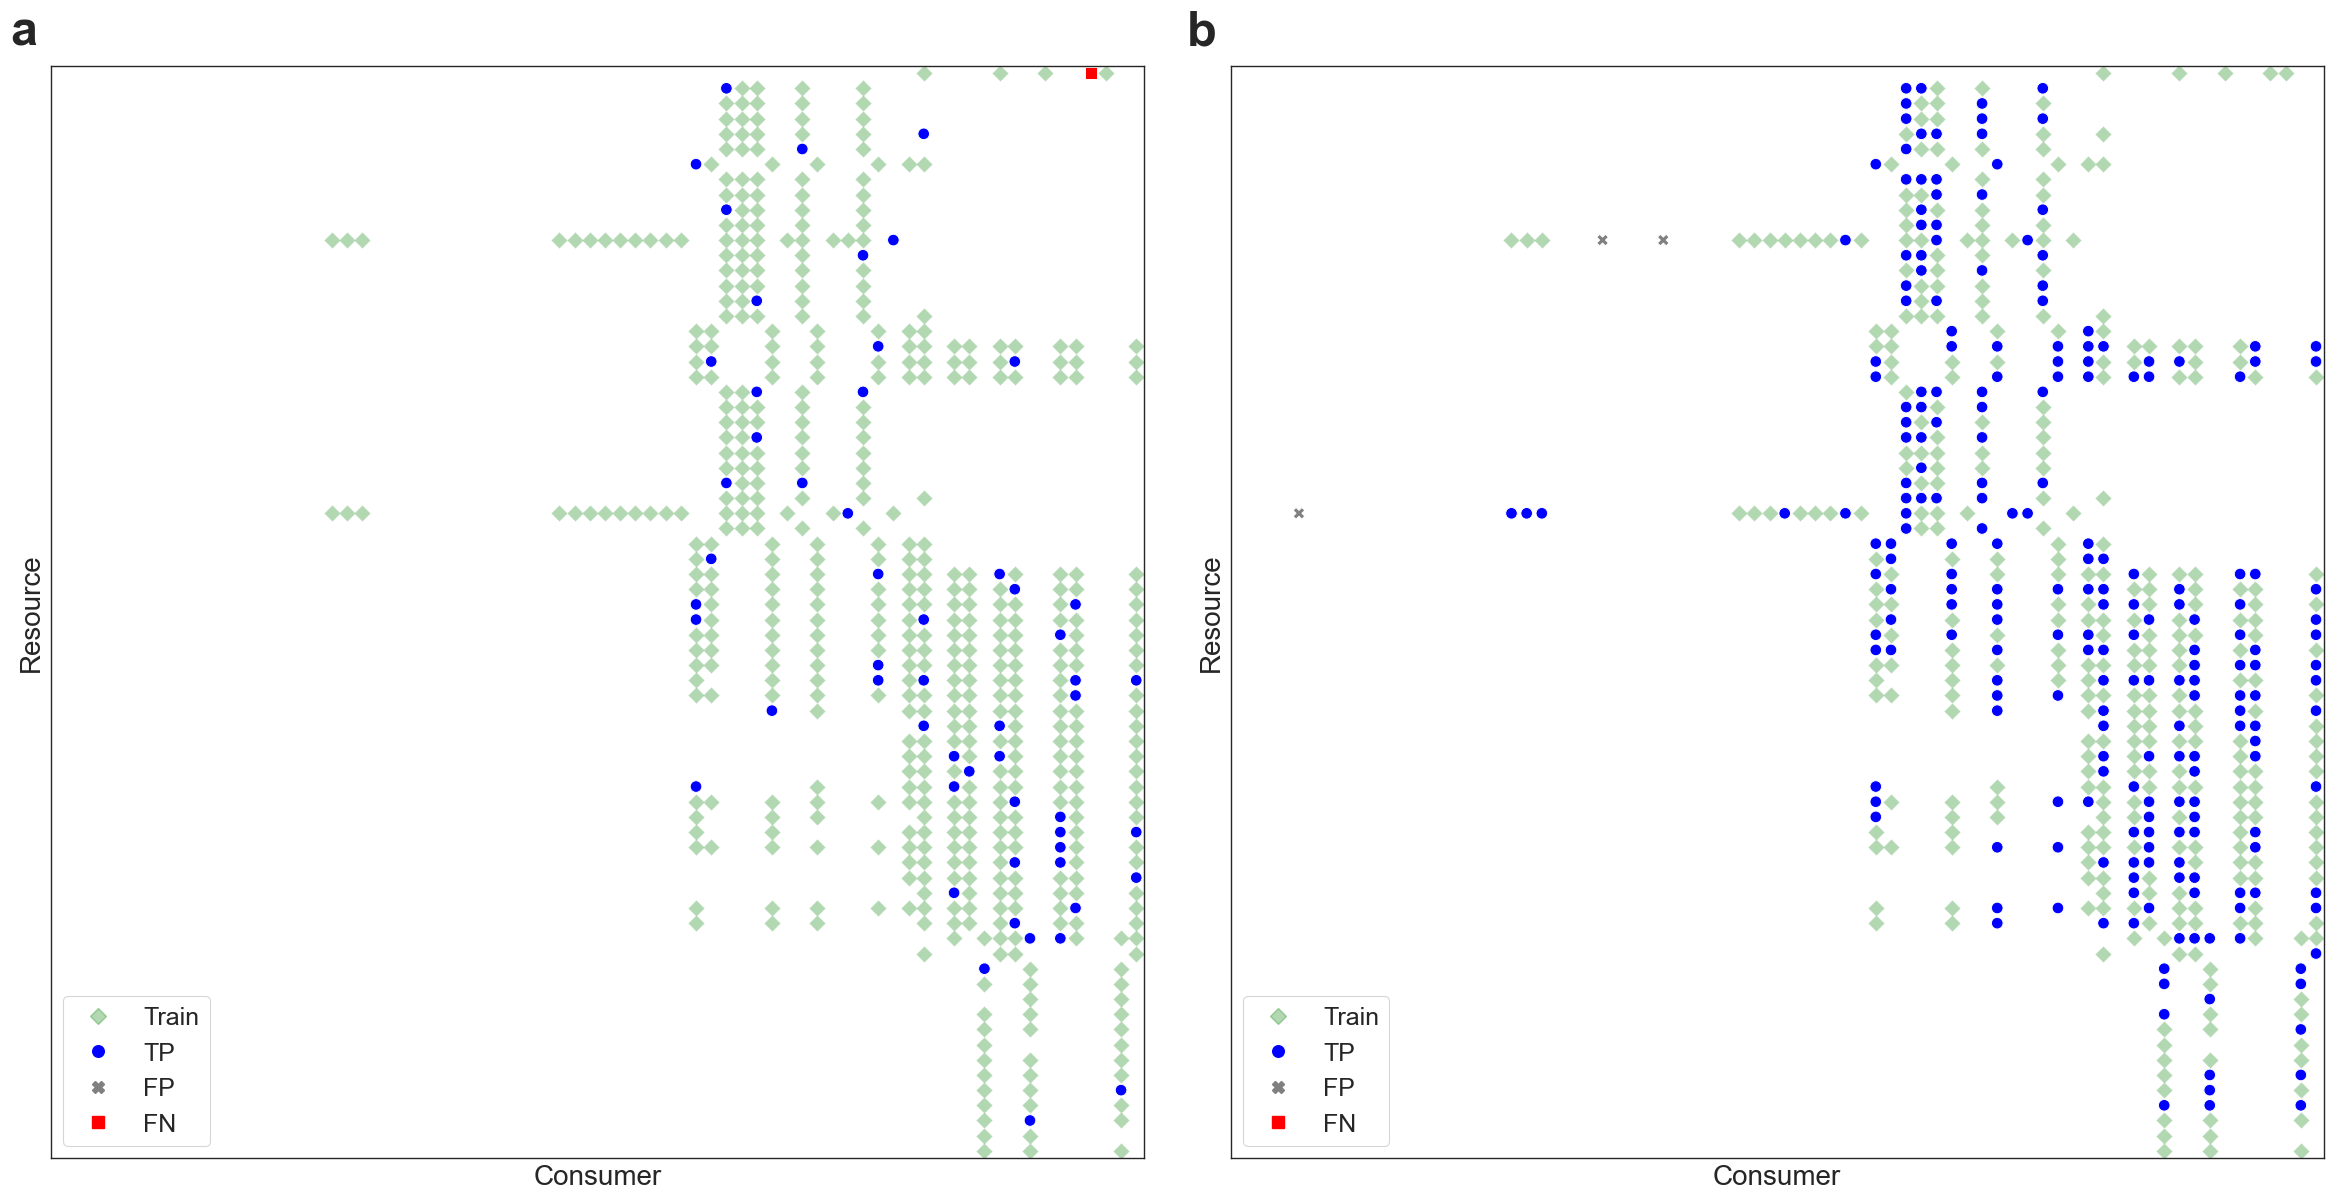

In [3]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.sparse import csr_matrix, issparse


# ============================================================
# Style + repository
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=3)


def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    for candidate in [start, *start.parents]:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        f"Could not locate repository root from {start}"
    )


REPO_ROOT = find_repo_root()


# ============================================================
# SIMPLE PANEL CONFIGURATION
# Edit foodweb, train_ratio and experiment_id per panel.
# train_ratio accepts 60 / 90 or 0.60 / 0.90.
# ============================================================

DEFAULT_FOODWEB = "Hoel lake"

PANELS = [
    {
        "letter": "a",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 90,
        "experiment_id": 1,
    },
    {
        "letter": "b",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 60,
        "experiment_id": 1,
    },
]

K_TARGET = 10
CLASSIFICATION_THRESHOLD = 0.50


# ============================================================
# Existing figure controls
# ============================================================

MIN_NODES = 40

SHOW_TITLES = False
SHOW_TICKS = False
USE_NUMERIC_AXIS_LABELS = False

XLAB = "Consumer"
YLAB = "Resource"

PANEL_XTICK_FONTSIZES = [12, 12]
PANEL_YTICK_FONTSIZES = [12, 12]

PRINT_SPECIES_KEY = False
EXPORT_SPECIES_KEY_FILE = True
SPECIES_KEY_FORMAT = "csv"

SPECIES_KEY_DIR = (
    REPO_ROOT
    / "docs/progress_notebooks_logs/2026/species_keys"
)


# ============================================================
# Input paths
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

PREDICTION_LOG_DIR = (
    RESULT_ROOT
    / "prediction_scores_logs"
)

ECOLOGICAL_SNAPSHOTS_DIR = (
    RESULT_ROOT
    / "ecological_snapshots"
)

BASE_MAT_PATH = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
)


# ============================================================
# Initial references
# Used only for the untouched initial configuration.
# Seeds are always read from the selected CSV row.
# ============================================================

def canonical_foodweb(name):
    name = str(name).strip()

    return (
        name[:-len("_tax_mass")]
        if name.endswith("_tax_mass")
        else name
    )


REFERENCE_FOODWEB = (
    "Grand Caricaie  marsh dominated by "
    "Cladietum marisci, not mown  ClControl2"
)


INITIAL_REFERENCE = {
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        60.0,
        21,
    ): {
        "seed": 1314098572,
        "TrainLinks": 460,
        "TestTP": 284,
        "TestFP": 8,
        "TestFN": 24,
    },
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        90.0,
        21,
    ): {
        "seed": 1316850472,
        "TrainLinks": 691,
        "TestTP": 39,
        "TestFP": 0,
        "TestFN": 38,
    },
}


# ============================================================
# Helpers
# ============================================================

def norm_name(value):
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def find_col(
    df,
    *aliases,
    required=True,
):
    lookup = {
        norm_name(column): column
        for column in df.columns
    }

    for alias in aliases:
        key = norm_name(alias)

        if key in lookup:
            return lookup[key]

    if required:
        raise KeyError(
            f"Missing required column. Tried {aliases}. "
            f"Available columns: {list(df.columns)}"
        )

    return None


def ratio_percent(value):
    value = float(value)

    if 0 < value <= 1:
        value *= 100

    if not 0 < value <= 100:
        raise ValueError(
            f"Invalid train_ratio={value!r}"
        )

    return float(value)


def tax_mass_stem(foodweb):
    foodweb = str(foodweb).strip()

    return (
        foodweb
        if foodweb.endswith("_tax_mass")
        else f"{foodweb}_tax_mass"
    )


def as_int(
    value,
    label,
):
    numeric = pd.to_numeric(
        pd.Series([value]),
        errors="coerce",
    ).iloc[0]

    if pd.isna(numeric):
        raise ValueError(
            f"{label} is not numeric: {value!r}"
        )

    integer = int(
        round(
            float(numeric)
        )
    )

    if not np.isclose(
        float(numeric),
        integer,
        atol=1e-9,
        rtol=0,
    ):
        raise ValueError(
            f"{label} is not an integer: {value!r}"
        )

    return integer


def binary_csr(matrix):
    if issparse(matrix):
        out = matrix.tocsr(
            copy=True
        )
    else:
        out = csr_matrix(
            np.asarray(matrix)
        )

    out.sum_duplicates()
    out.eliminate_zeros()

    if out.nnz:
        out.data = np.ones(
            out.nnz,
            dtype=np.int8,
        )

    return out.astype(
        np.int8
    )


def mask_and(
    a,
    b,
):
    out = a.multiply(
        b
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        out.data[:] = 1

    return out


def mask_and_not(
    a,
    b,
):
    out = (
        a.astype(np.int8)
        - a.multiply(b).astype(np.int8)
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        if np.any(
            out.data < 0
        ):
            raise ValueError(
                "Unexpected negative entries while "
                "reconstructing sparse masks."
            )

        out.data[:] = 1

    return out


def sparse_equal(
    a,
    b,
):
    if a.shape != b.shape:
        return False

    diff = (
        a.astype(np.int8)
        - b.astype(np.int8)
    ).tocsr()

    diff.eliminate_zeros()

    return (
        diff.nnz == 0
    )


def unwrap(value):
    while (
        isinstance(
            value,
            np.ndarray,
        )
        and value.size == 1
    ):
        value = value.reshape(
            -1
        )[0]

    return value


def matlab_str(value):
    value = unwrap(
        value
    )

    if isinstance(
        value,
        (bytes, np.bytes_),
    ):
        return bytes(
            value
        ).decode(
            "utf-8",
            errors="replace",
        ).strip()

    if isinstance(
        value,
        str,
    ):
        return value.strip()

    if isinstance(
        value,
        np.str_,
    ):
        return str(
            value
        ).strip()

    if (
        isinstance(
            value,
            np.ndarray,
        )
        and value.dtype.kind
        in {
            "U",
            "S",
        }
    ):
        parts = []

        for item in value.reshape(
            -1
        ):
            if isinstance(
                item,
                (bytes, np.bytes_),
            ):
                parts.append(
                    bytes(
                        item
                    ).decode(
                        "utf-8",
                        errors="replace",
                    )
                )

            else:
                parts.append(
                    str(
                        item
                    )
                )

        return "".join(
            parts
        ).strip()

    return str(
        value
    ).strip()


def matlab_str_list(value):
    return [
        matlab_str(
            item
        )
        for item
        in np.asarray(
            value,
            dtype=object,
        ).reshape(-1)
    ]


def struct_fields(obj):
    obj = unwrap(
        obj
    )

    if isinstance(
        obj,
        dict,
    ):
        return list(
            obj.items()
        )

    names = getattr(
        obj,
        "_fieldnames",
        None,
    )

    if names:
        return [
            (
                name,
                getattr(
                    obj,
                    name,
                ),
            )
            for name in names
        ]

    if (
        isinstance(
            obj,
            np.void,
        )
        and obj.dtype.names
    ):
        return [
            (
                name,
                obj[name],
            )
            for name
            in obj.dtype.names
        ]

    return []


def struct_get(
    obj,
    field,
):
    target = norm_name(
        field
    )

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) == target:
            return value

    raise KeyError(
        f"MATLAB struct is missing field "
        f"{field!r}. "
        f"Available fields: "
        f"{[name for name, _ in struct_fields(obj)]}"
    )


def struct_get_optional(
    obj,
    *aliases,
):
    targets = {
        norm_name(alias)
        for alias in aliases
    }

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) in targets:
            return value

    return None


# ============================================================
# Exact CSV row selection
# ============================================================

def select_run(panel):
    foodweb = panel[
        "foodweb"
    ]

    ratio = ratio_percent(
        panel[
            "train_ratio"
        ]
    )

    experiment_id = int(
        panel[
            "experiment_id"
        ]
    )

    csv_path = (
        PREDICTION_LOG_DIR
        / (
            f"{tax_mass_stem(foodweb)}"
            "_results_random_wlnm_dir_neg.csv"
        )
    )

    if not csv_path.is_file():
        raise FileNotFoundError(
            "Results CSV not found:\n"
            f"  {csv_path}"
        )

    df = pd.read_csv(
        csv_path
    )

    k_col = find_col(
        df,
        "K",
        "SubgraphK",
    )

    ratio_col = find_col(
        df,
        "TrainRatio",
        "TrainingRatio",
    )

    exp_col = find_col(
        df,
        "ExperimentID",
        "Experiment",
    )

    threshold_col = find_col(
        df,
        "Threshold",
        "ClassificationThreshold",
    )

    foodweb_col = find_col(
        df,
        "Foodweb",
        "FoodWebName",
        required=False,
    )

    k = pd.to_numeric(
        df[k_col],
        errors="coerce",
    )

    train_ratio = pd.to_numeric(
        df[ratio_col],
        errors="coerce",
    )

    train_ratio = np.where(
        train_ratio
        <= 1.0 + 1e-12,
        train_ratio * 100.0,
        train_ratio,
    )

    experiment = pd.to_numeric(
        df[exp_col],
        errors="coerce",
    )

    threshold = pd.to_numeric(
        df[threshold_col],
        errors="coerce",
    )

    mask = (
        np.isclose(
            k,
            K_TARGET,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            train_ratio,
            ratio,
            atol=1e-9,
            rtol=0,
        )
        & np.isclose(
            experiment,
            experiment_id,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            threshold,
            CLASSIFICATION_THRESHOLD,
            atol=1e-12,
            rtol=0,
        )
    )

    if (
        foodweb_col
        is not None
    ):
        mask &= (
            df[foodweb_col]
            .astype(str)
            .map(
                canonical_foodweb
            )
            .eq(
                canonical_foodweb(
                    foodweb
                )
            )
        )

    matches = df.loc[
        mask
    ]

    if len(
        matches
    ) != 1:
        raise ValueError(
            "Expected exactly one matching run, "
            f"but found {len(matches)}.\n"
            f"  foodweb={foodweb!r}\n"
            f"  K={K_TARGET}\n"
            f"  TrainRatio={ratio:g}%\n"
            f"  ExperimentID={experiment_id}\n"
            f"  threshold={CLASSIFICATION_THRESHOLD}\n"
            f"  CSV={csv_path}"
        )

    return (
        matches.iloc[0],
        csv_path,
        ratio,
    )


# ============================================================
# Resolve LOCAL snapshot by basename only
# ============================================================

def local_snapshot_from_row(row):
    row_df = pd.DataFrame(
        [row]
    )

    snapshot_col = find_col(
        row_df,
        "TrophicSnapshotFile",
        "SnapshotFile",
    )

    raw = row[
        snapshot_col
    ]

    if pd.isna(
        raw
    ):
        raise ValueError(
            "TrophicSnapshotFile is empty "
            "for the selected run."
        )

    snapshot_name = (
        str(raw)
        .strip()
        .replace(
            "\\",
            "/",
        )
        .split("/")[-1]
    )

    matches = [
        path
        for path
        in ECOLOGICAL_SNAPSHOTS_DIR.rglob(
            "*.mat"
        )
        if path.name
        == snapshot_name
    ]

    if len(
        matches
    ) != 1:
        raise FileNotFoundError(
            "Expected exactly one LOCAL "
            "ecological snapshot, "
            f"found {len(matches)}.\n"
            f"  basename={snapshot_name!r}\n"
            f"  searched under="
            f"{ECOLOGICAL_SNAPSHOTS_DIR}\n"
            f"  matches={matches}"
        )

    return matches[0]


# ============================================================
# Load tax/mass file
# ============================================================

def load_tax_mass(foodweb):
    mat_path = (
        BASE_MAT_PATH
        / (
            f"{tax_mass_stem(foodweb)}"
            ".mat"
        )
    )

    if not mat_path.is_file():
        raise FileNotFoundError(
            "Food-web tax/mass MAT "
            "not found:\n"
            f"  {mat_path}"
        )

    data = scipy.io.loadmat(
        mat_path,
        struct_as_record=False,
        squeeze_me=True,
    )

    for key in (
        "net",
        "taxonomy",
        "mass",
    ):
        if key not in data:
            raise KeyError(
                f"{mat_path} "
                f"is missing {key!r}"
            )

    net = binary_csr(
        data[
            "net"
        ]
    )
    # WLNM_dir_neg removes self-loops before saving empirical.
    net.setdiag(0)
    net.eliminate_zeros()

    taxonomy = matlab_str_list(
        data[
            "taxonomy"
        ]
    )

    mass = np.asarray(
        data[
            "mass"
        ]
    ).reshape(
        -1
    ).astype(
        float
    )

    n = len(
        taxonomy
    )

    if len(
        mass
    ) != n:
        raise ValueError(
            "taxonomy and mass "
            "have different lengths in "
            f"{mat_path}"
        )

    if net.shape != (
        n,
        n,
    ):
        raise ValueError(
            f"net.shape={net.shape}, "
            f"expected {(n, n)}"
        )

    if n < MIN_NODES:
        raise ValueError(
            f"Selected food web has "
            f"{n} nodes, below "
            f"MIN_NODES={MIN_NODES}."
        )

    if not np.all(
        np.isfinite(
            mass
        )
    ):
        raise ValueError(
            "Non-finite body masses "
            f"found in {mat_path}"
        )

    normalized = [
        re.sub(
            r"\s+",
            " ",
            value.strip(),
        )
        for value
        in taxonomy
    ]

    if len(
        set(
            normalized
        )
    ) != n:
        raise ValueError(
            "Duplicate taxonomy labels "
            "found; node mapping is ambiguous."
        )

    return (
        mat_path,
        net,
        taxonomy,
        mass,
    )


# ============================================================
# Load snapshot + reconstruct Train / TP / FP / FN
# ============================================================

def load_snapshot(
    snapshot_path,
    base_net,
    taxonomy,
):
    data = scipy.io.loadmat(
        snapshot_path,
        struct_as_record=False,
        squeeze_me=True,
    )

    if (
        "snapshot"
        not in data
    ):
        raise KeyError(
            "'snapshot' struct "
            "not found in "
            f"{snapshot_path}"
        )

    snapshot = data[
        "snapshot"
    ]

    empirical = binary_csr(
        struct_get(
            snapshot,
            "empirical",
        )
    )

    train = binary_csr(
        struct_get(
            snapshot,
            "train",
        )
    )

    pseudo = binary_csr(
        struct_get(
            snapshot,
            "pseudo",
        )
    )

    metadata = struct_get(
        snapshot,
        "metadata",
    )

    n = len(
        taxonomy
    )

    for name, matrix in {
        "empirical": empirical,
        "train": train,
        "pseudo": pseudo,
    }.items():

        if matrix.shape != (
            n,
            n,
        ):
            raise ValueError(
                f"snapshot.{name}.shape="
                f"{matrix.shape}, "
                f"expected {(n, n)}"
            )

    # Validate snapshot node indexing and direction against
    # the original directed food-web matrix.
    if not sparse_equal(
        empirical,
        base_net,
    ):
        if sparse_equal(
            empirical,
            base_net.T.tocsr(),
        ):
            raise ValueError(
                "snapshot.empirical matches "
                "net.T rather than net. "
                "Direction/index convention "
                "is inconsistent."
            )

        raise ValueError(
            "snapshot.empirical does not "
            "match the tax_mass net. "
            "Node identity/order cannot "
            "be validated safely."
        )

    train_outside_empirical = (
        mask_and_not(
            train,
            empirical,
        )
    )

    if (
        train_outside_empirical.nnz
    ):
        raise ValueError(
            "snapshot.train contains "
            f"{train_outside_empirical.nnz} "
            "links absent from empirical."
        )

    # If metadata exposes node names, verify those explicitly too.
    metadata_nodes = struct_get_optional(
        metadata,
        "taxonomy",
        "taxa",
        "species",
        "species_names",
        "node_names",
        "node_labels",
    )

    if (
        metadata_nodes
        is not None
    ):
        names = matlab_str_list(
            metadata_nodes
        )

        if len(
            names
        ) == n:

            def clean(value):
                return re.sub(
                    r"\s+",
                    " ",
                    value.strip(),
                )

            if (
                list(
                    map(
                        clean,
                        names,
                    )
                )
                != list(
                    map(
                        clean,
                        taxonomy,
                    )
                )
            ):
                raise ValueError(
                    "Snapshot metadata node names "
                    "do not match tax_mass taxonomy "
                    "in the same index order."
                )

            print(
                "[INFO] Snapshot node names "
                "match tax_mass taxonomy."
            )

    # --------------------------------------------------------
    # Required reconstruction
    # --------------------------------------------------------
    #
    # Train          = train
    # true_test      = empirical & ~train
    # predicted_test = pseudo & ~train
    # TP             = true_test & predicted_test
    # FP             = predicted_test & ~true_test
    # FN             = true_test & ~predicted_test
    #

    true_test = mask_and_not(
        empirical,
        train,
    )

    predicted_test = mask_and_not(
        pseudo,
        train,
    )

    tp = mask_and(
        true_test,
        predicted_test,
    )

    fp = mask_and_not(
        predicted_test,
        true_test,
    )

    fn = mask_and_not(
        true_test,
        predicted_test,
    )

    return {
        "Train": train,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "metadata": metadata,
    }


# ============================================================
# Validate seed + reconstructed counts against selected CSV row
# ============================================================

def validate_run(
    row,
    panel,
    ratio,
    masks,
    snapshot_path,
):
    row_df = pd.DataFrame(
        [row]
    )

    seed_col = find_col(
        row_df,
        "Seed",
        "RandomSeed",
        "ExperimentSeed",
    )

    train_col = find_col(
        row_df,
        "TrainLinks",
    )

    tp_col = find_col(
        row_df,
        "TestTP",
    )

    fp_col = find_col(
        row_df,
        "TestFP",
    )

    fn_col = find_col(
        row_df,
        "TestFN",
    )

    seed = as_int(
        row[
            seed_col
        ],
        "Seed",
    )

    csv_counts = {
        "TrainLinks": as_int(
            row[
                train_col
            ],
            "TrainLinks",
        ),
        "TestTP": as_int(
            row[
                tp_col
            ],
            "TestTP",
        ),
        "TestFP": as_int(
            row[
                fp_col
            ],
            "TestFP",
        ),
        "TestFN": as_int(
            row[
                fn_col
            ],
            "TestFN",
        ),
    }

    reconstructed = {
        "TrainLinks": (
            masks[
                "Train"
            ].nnz
        ),
        "TestTP": (
            masks[
                "TP"
            ].nnz
        ),
        "TestFP": (
            masks[
                "FP"
            ].nnz
        ),
        "TestFN": (
            masks[
                "FN"
            ].nnz
        ),
    }

    if (
        csv_counts
        != reconstructed
    ):
        raise ValueError(
            "Reconstructed counts do not "
            "match the selected CSV row.\n"
            f"  CSV={csv_counts}\n"
            f"  reconstructed={reconstructed}\n"
            f"  snapshot={snapshot_path}"
        )

    # If metadata contains its own seed, verify that too.
    metadata_seed = struct_get_optional(
        masks[
            "metadata"
        ],
        "seed",
        "random_seed",
        "experiment_seed",
    )

    if (
        metadata_seed
        is not None
    ):
        snapshot_seed = as_int(
            unwrap(
                metadata_seed
            ),
            "snapshot metadata seed",
        )

        if (
            snapshot_seed
            != seed
        ):
            raise ValueError(
                "Seed mismatch between CSV "
                "and snapshot metadata:\n"
                f"  CSV={seed}\n"
                f"  snapshot={snapshot_seed}"
            )

    # Only the untouched initial configuration is checked
    # against the supplied reference seed/counts.
    ref_key = (
        canonical_foodweb(
            panel[
                "foodweb"
            ]
        ),
        float(
            ratio
        ),
        int(
            panel[
                "experiment_id"
            ]
        ),
    )

    reference = INITIAL_REFERENCE.get(
        ref_key
    )

    if (
        reference
        is not None
    ):
        if (
            seed
            != reference[
                "seed"
            ]
        ):
            raise ValueError(
                "Initial seed does not match "
                "the supplied reference:\n"
                f"  expected="
                f"{reference['seed']}\n"
                f"  CSV={seed}"
            )

        for key in (
            "TrainLinks",
            "TestTP",
            "TestFP",
            "TestFN",
        ):
            if (
                reconstructed[
                    key
                ]
                != reference[
                    key
                ]
            ):
                raise ValueError(
                    "Initial reference mismatch "
                    f"for {key}: "
                    f"expected={reference[key]}, "
                    f"observed={reconstructed[key]}"
                )

    return (
        seed,
        reconstructed,
    )


# ============================================================
# Sparse directed links -> mass-sorted plotting coordinates
#
# Matrix convention:
#   row    = Resource / Prey
#   column = Consumer / Predator
# ============================================================

def mask_to_df(
    mask,
    original_to_sorted,
    label,
):
    (
        resource_idx,
        consumer_idx,
    ) = mask.nonzero()

    return pd.DataFrame({
        "PreyIdx": (
            original_to_sorted[
                resource_idx
            ]
        ),
        "PredIdx": (
            original_to_sorted[
                consumer_idx
            ]
        ),
        "Label": label,
    })


# ============================================================
# Validate ALL panels before drawing
# ============================================================

for label, path in {
    "prediction_scores_logs":
        PREDICTION_LOG_DIR,
    "ecological_snapshots":
        ECOLOGICAL_SNAPSHOTS_DIR,
    "foodwebs_mat":
        BASE_MAT_PATH,
}.items():

    if not path.is_dir():
        raise FileNotFoundError(
            f"Missing {label} directory:\n"
            f"  {path}"
        )


prepared = []
tax_mass_cache = {}
species_key_done = set()


for panel_idx, panel in enumerate(
    PANELS
):
    letter = panel.get(
        "letter",
        chr(
            ord("a")
            + panel_idx
        ),
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"[INFO] Panel {letter}: "
        f"{canonical_foodweb(panel['foodweb'])}"
    )

    # --------------------------------------------------------
    # 1. Locate exactly one run in prediction_scores_logs
    # --------------------------------------------------------

    (
        row,
        results_csv,
        ratio,
    ) = select_run(
        panel
    )

    # --------------------------------------------------------
    # 2. Resolve LOCAL snapshot from TrophicSnapshotFile basename
    # --------------------------------------------------------

    snapshot_path = (
        local_snapshot_from_row(
            row
        )
    )

    # --------------------------------------------------------
    # 3. Load taxonomy / mass / empirical net
    # --------------------------------------------------------

    stem = tax_mass_stem(
        panel[
            "foodweb"
        ]
    )

    if (
        stem
        not in tax_mass_cache
    ):
        tax_mass_cache[
            stem
        ] = load_tax_mass(
            panel[
                "foodweb"
            ]
        )

    (
        tax_mass_path,
        base_net,
        taxonomy,
        mass,
    ) = tax_mass_cache[
        stem
    ]

    # --------------------------------------------------------
    # 4. Load snapshot and reconstruct Train / TP / FP / FN
    # --------------------------------------------------------

    masks = load_snapshot(
        snapshot_path,
        base_net,
        taxonomy,
    )

    # --------------------------------------------------------
    # 5. Validate seed and reconstructed counts
    # --------------------------------------------------------

    (
        seed,
        counts,
    ) = validate_run(
        row=row,
        panel=panel,
        ratio=ratio,
        masks=masks,
        snapshot_path=snapshot_path,
    )

    print(
        "[INFO] Exact run validated:\n"
        f"  K={K_TARGET}, "
        f"TrainRatio={ratio:g}%, "
        f"ExperimentID="
        f"{panel['experiment_id']}, "
        f"threshold="
        f"{CLASSIFICATION_THRESHOLD:.2f}\n"
        f"  Seed={seed}\n"
        f"  Train="
        f"{counts['TrainLinks']:,}, "
        f"TP={counts['TestTP']:,}, "
        f"FP={counts['TestFP']:,}, "
        f"FN={counts['TestFN']:,}\n"
        f"  CSV={results_csv}\n"
        f"  Snapshot={snapshot_path}"
    )

    # --------------------------------------------------------
    # 6. Sort species by body mass
    # --------------------------------------------------------

    # Same conversion used by the original cell.
    mass_mg = np.round(
        mass * 1000.0,
        4,
    )

    sorted_original_idx = np.argsort(
        mass_mg,
        kind="stable",
    )

    sorted_species = [
        taxonomy[
            index
        ]
        for index
        in sorted_original_idx
    ]

    sorted_mass_mg = (
        mass_mg[
            sorted_original_idx
        ]
    )

    n = len(
        sorted_species
    )

    original_to_sorted = np.empty(
        n,
        dtype=int,
    )

    original_to_sorted[
        sorted_original_idx
    ] = np.arange(
        n
    )

    # Stable numbering for the same food web in both panels.
    species_to_num = {
        species: index + 1
        for index, species
        in enumerate(
            sorted_species
        )
    }

    # --------------------------------------------------------
    # Optional species key
    # --------------------------------------------------------

    if (
        PRINT_SPECIES_KEY
        and stem
        not in species_key_done
    ):
        key_df = pd.DataFrame({
            "Number": np.arange(
                1,
                n + 1,
            ),
            "Species":
                sorted_species,
            "Mass_mg":
                sorted_mass_mg,
        })

        key_df[
            "Mass_mg"
        ] = (
            key_df[
                "Mass_mg"
            ]
            .map(
                lambda value:
                f"{value:.4f}"
            )
        )

        print(
            "\n"
            + key_df.to_string(
                index=False
            )
        )

        if (
            EXPORT_SPECIES_KEY_FILE
        ):
            SPECIES_KEY_DIR.mkdir(
                parents=True,
                exist_ok=True,
            )

            safe_foodweb = re.sub(
                r"[^A-Za-z0-9._-]+",
                "_",
                stem,
            ).strip(
                "_"
            )

            extension = (
                "tsv"
                if (
                    SPECIES_KEY_FORMAT.lower()
                    == "tsv"
                )
                else "csv"
            )

            output_path = (
                SPECIES_KEY_DIR
                / (
                    f"{safe_foodweb}_"
                    f"species_key."
                    f"{extension}"
                )
            )

            key_df.to_csv(
                output_path,
                sep=(
                    "\t"
                    if extension
                    == "tsv"
                    else ","
                ),
                index=False,
                encoding="utf-8",
            )

            print(
                "[INFO] Saved species key: "
                f"{output_path.resolve()}"
            )

        species_key_done.add(
            stem
        )

    # --------------------------------------------------------
    # 7. Convert reconstructed matrices to plot coordinates
    # --------------------------------------------------------

    df_train = mask_to_df(
        masks[
            "Train"
        ],
        original_to_sorted,
        "Train",
    )

    df_pm = pd.concat(
        [
            mask_to_df(
                masks[
                    "TP"
                ],
                original_to_sorted,
                "TP",
            ),
            mask_to_df(
                masks[
                    "FP"
                ],
                original_to_sorted,
                "FP",
            ),
            mask_to_df(
                masks[
                    "FN"
                ],
                original_to_sorted,
                "FN",
            ),
        ],
        ignore_index=True,
    )

    prepared.append({
        "letter":
            letter,
        "foodweb":
            canonical_foodweb(
                panel[
                    "foodweb"
                ]
            ),
        "train_ratio":
            ratio,
        "experiment_id":
            int(
                panel[
                    "experiment_id"
                ]
            ),
        "seed":
            seed,
        "n":
            n,
        "sorted_species":
            sorted_species,
        "species_to_num":
            species_to_num,
        "df_train":
            df_train,
        "df_pm":
            df_pm,
    })


# ============================================================
# Plot only AFTER every panel has passed all checks
# ============================================================

fig, axs = plt.subplots(
    1,
    len(
        prepared
    ),
    figsize=(
        12 * len(
            prepared
        ),
        12,
    ),
    squeeze=False,
)

axs = axs.ravel()


# Keep Train / TP / FP / FN in every legend,
# including FP when FP=0 in panel b.
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="None",
        markerfacecolor="green",
        markeredgecolor="green",
        alpha=0.3,
        markersize=np.sqrt(
            70
        ),
        label="Train",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="blue",
        markeredgecolor="blue",
        markersize=np.sqrt(
            70
        ),
        label="TP",
    ),
    Line2D(
        [0],
        [0],
        marker="X",
        linestyle="None",
        markerfacecolor="gray",
        markeredgecolor="gray",
        markersize=np.sqrt(
            70
        ),
        label="FP",
    ),
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=np.sqrt(
            70
        ),
        label="FN",
    ),
]


for panel_idx, panel in enumerate(
    prepared
):
    ax = axs[
        panel_idx
    ]

    n = panel[
        "n"
    ]

    # --------------------------------------------------------
    # Training links first
    # green diamond, alpha=0.3, s=70
    # --------------------------------------------------------

    if not panel[
        "df_train"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_train"
            ],
            x="PredIdx",
            y="PreyIdx",
            color="green",
            marker="D",
            alpha=0.3,
            s=70,
            legend=False,
            ax=ax,
        )

    # --------------------------------------------------------
    # TP / FP / FN
    # --------------------------------------------------------

    if not panel[
        "df_pm"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_pm"
            ],
            x="PredIdx",
            y="PreyIdx",
            hue="Label",
            style="Label",
            hue_order=[
                "TP",
                "FP",
                "FN",
            ],
            style_order=[
                "TP",
                "FP",
                "FN",
            ],
            markers={
                "TP": "o",
                "FP": "X",
                "FN": "s",
            },
            palette={
                "TP": "blue",
                "FP": "gray",
                "FN": "red",
            },
            s=70,
            legend=False,
            ax=ax,
        )

    # Consumer body mass increases left -> right.
    ax.set_xlim(
        -0.5,
        n - 0.5,
    )

    # Resource body mass increases top -> bottom.
    ax.set_ylim(
        n - 0.5,
        -0.5,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlabel(
        XLAB,
        fontsize=20,
    )

    ax.set_ylabel(
        YLAB,
        fontsize=20,
    )

    # --------------------------------------------------------
    # Existing tick controls
    # --------------------------------------------------------

    if SHOW_TICKS:
        ax.set_xticks(
            range(
                n
            )
        )

        ax.set_yticks(
            range(
                n
            )
        )

        x_fontsize = (
            PANEL_XTICK_FONTSIZES[
                panel_idx
            ]
        )

        y_fontsize = (
            PANEL_YTICK_FONTSIZES[
                panel_idx
            ]
        )

        if (
            USE_NUMERIC_AXIS_LABELS
        ):
            labels = [
                str(
                    panel[
                        "species_to_num"
                    ][
                        species
                    ]
                )
                for species
                in panel[
                    "sorted_species"
                ]
            ]

            ax.set_xticklabels(
                labels,
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                labels,
                fontsize=y_fontsize,
            )

        else:
            ax.set_xticklabels(
                panel[
                    "sorted_species"
                ],
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                panel[
                    "sorted_species"
                ],
                fontsize=y_fontsize,
            )

        ax.tick_params(
            axis="both",
            which="both",
            length=3,
        )

    else:
        ax.set_xticks(
            []
        )

        ax.set_yticks(
            []
        )

        ax.set_xticklabels(
            []
        )

        ax.set_yticklabels(
            []
        )

        ax.tick_params(
            axis="both",
            which="both",
            length=0,
        )

    # --------------------------------------------------------
    # Existing title control
    # --------------------------------------------------------

    if SHOW_TITLES:
        ax.set_title(
            panel[
                "foodweb"
            ],
            fontsize=12,
        )

    # --------------------------------------------------------
    # Panel letter outside matrix
    # --------------------------------------------------------

    ax.annotate(
        panel["letter"],
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(-10, 8),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=35,
        fontweight="bold",
        annotation_clip=False,
    )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        handles=legend_handles,
        loc="lower left",
        prop={
            "size": 18,
        },
        title="",
    )


plt.tight_layout()
plt.show()


[INFO] Panel a: Hoel lake
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=90%, ExperimentID=1, threshold=0.50
  Seed=1804283525
  Train=507, TP=56, FP=0, FN=1
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs/Hoel lake_tax_mass_results_random_wlnm_dir_neg.csv
  Snapshot=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/ecological_snapshots/Hoel_lake_tax_mass_K10_ratio0.9_exp1_seed1804283525_threshold0.5_validated_v2.mat

[INFO] Panel b: Hoel lake
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=60%, ExperimentID=1, threshold=0.50
  Seed=1801531625
  Train=338, TP=226, FP=3, FN=0
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_troph

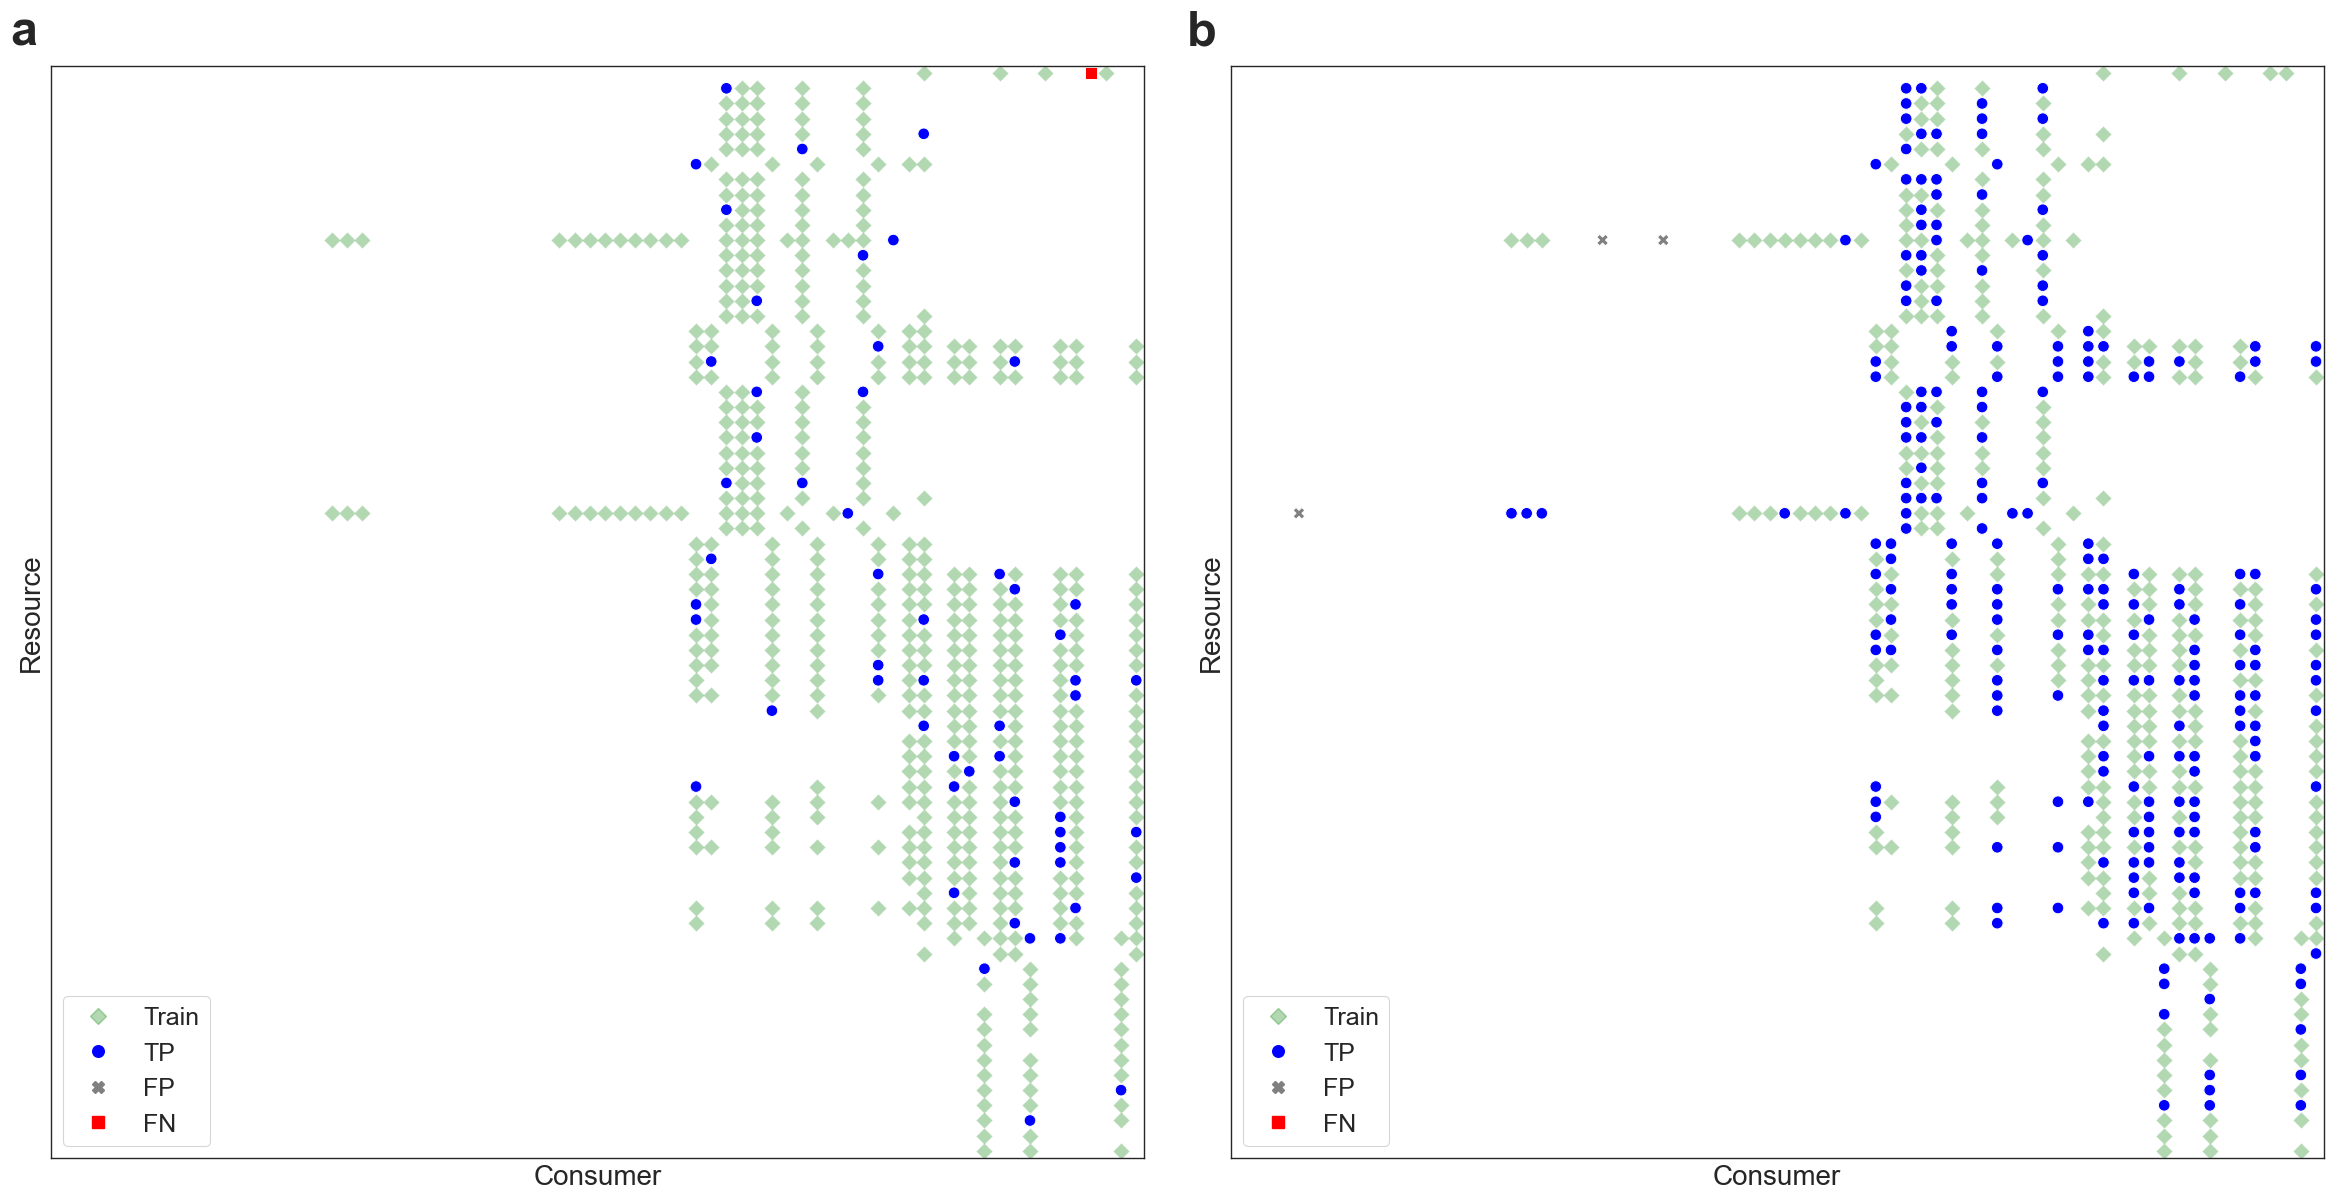

[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snapshot node names match tax_mass taxonomy.
[TOP20] 01/20 Bridge brook lake: ExperimentID=64, 90% TP/FP/FN=55/0/0, 60% TP/FP/FN=220/5/0
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snapshot node names match tax_mass taxonomy.
[TOP20] 02/20 Hoel lake: ExperimentID=77, 90% TP/FP/FN=56/0/1, 60% TP/FP/FN=221/2/5
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snapshot node names match tax_mass taxonomy.
[TOP20] 03/20 Connera lake: ExperimentID=71, 90% TP/FP/FN=42/1/0, 60% TP/FP/FN=160/1/5
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snapshot node names match tax_mass taxonomy.
[TOP20] 04/20 Big hope lake: ExperimentID=37, 90% TP/FP/FN=32/0/1, 60% TP/FP/FN=125/2/4
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snapshot node names match tax_mass taxonomy.
[TOP20] 05/20 Gearagh: ExperimentID=38, 90% TP/FP/FN=29/0/9, 60% TP/FP/FN=126/9/25
[INFO] Snapshot node names match tax_mass taxo

{'__name__': '<run_path>',
 '__doc__': "Generate the 20 ranked Figure 2 options used by week-42.ipynb cell 5.\n\nThis file is executed with ``runpy.run_path(..., init_globals=globals())``\nfrom the notebook.  It deliberately reuses the notebook's validated data\nloaders and its existing plotting constants so the exported alternatives use\nthe same data semantics and visual style as the single-food-web panels.\n",
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__builtin__': <module 'builtins' (built-in)>,
 '__builtins__': <module 'builtins' (built-in)>,
 '_ih': ['',
  'import re\nfrom pathlib import Path\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport scipy.io\nimport seaborn as sns\nfrom matplotlib.lines import Line2D\nfrom scipy.sparse import csr_matrix, issparse\n\n\n# ============================================================\n# Style + repository\n# ============================================================\n\nsns.set_theme(con

In [4]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.sparse import csr_matrix, issparse


# ============================================================
# Style + repository
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=3)


def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    for candidate in [start, *start.parents]:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        f"Could not locate repository root from {start}"
    )


REPO_ROOT = find_repo_root()


# ============================================================
# SIMPLE PANEL CONFIGURATION
# Edit foodweb, train_ratio and experiment_id per panel.
# train_ratio accepts 60 / 90 or 0.60 / 0.90.
# ============================================================

DEFAULT_FOODWEB = "Hoel lake"

PANELS = [
    {
        "letter": "a",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 90,
        "experiment_id": 1,
    },
    {
        "letter": "b",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 60,
        "experiment_id": 1,
    },
]

K_TARGET = 10
CLASSIFICATION_THRESHOLD = 0.50


# ============================================================
# Existing figure controls
# ============================================================

MIN_NODES = 40

SHOW_TITLES = False
SHOW_TICKS = False
USE_NUMERIC_AXIS_LABELS = False

XLAB = "Consumer"
YLAB = "Resource"

PANEL_XTICK_FONTSIZES = [12, 12]
PANEL_YTICK_FONTSIZES = [12, 12]

PRINT_SPECIES_KEY = False
EXPORT_SPECIES_KEY_FILE = True
SPECIES_KEY_FORMAT = "csv"

SPECIES_KEY_DIR = (
    REPO_ROOT
    / "docs/progress_notebooks_logs/2026/species_keys"
)


# ============================================================
# Input paths
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

PREDICTION_LOG_DIR = (
    RESULT_ROOT
    / "prediction_scores_logs"
)

ECOLOGICAL_SNAPSHOTS_DIR = (
    RESULT_ROOT
    / "ecological_snapshots"
)

BASE_MAT_PATH = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
)


# ============================================================
# Initial references
# Used only for the untouched initial configuration.
# Seeds are always read from the selected CSV row.
# ============================================================

def canonical_foodweb(name):
    name = str(name).strip()

    return (
        name[:-len("_tax_mass")]
        if name.endswith("_tax_mass")
        else name
    )


REFERENCE_FOODWEB = (
    "Grand Caricaie  marsh dominated by "
    "Cladietum marisci, not mown  ClControl2"
)


INITIAL_REFERENCE = {
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        60.0,
        21,
    ): {
        "seed": 1314098572,
        "TrainLinks": 460,
        "TestTP": 284,
        "TestFP": 8,
        "TestFN": 24,
    },
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        90.0,
        21,
    ): {
        "seed": 1316850472,
        "TrainLinks": 691,
        "TestTP": 39,
        "TestFP": 0,
        "TestFN": 38,
    },
}


# ============================================================
# Helpers
# ============================================================

def norm_name(value):
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def find_col(
    df,
    *aliases,
    required=True,
):
    lookup = {
        norm_name(column): column
        for column in df.columns
    }

    for alias in aliases:
        key = norm_name(alias)

        if key in lookup:
            return lookup[key]

    if required:
        raise KeyError(
            f"Missing required column. Tried {aliases}. "
            f"Available columns: {list(df.columns)}"
        )

    return None


def ratio_percent(value):
    value = float(value)

    if 0 < value <= 1:
        value *= 100

    if not 0 < value <= 100:
        raise ValueError(
            f"Invalid train_ratio={value!r}"
        )

    return float(value)


def tax_mass_stem(foodweb):
    foodweb = str(foodweb).strip()

    return (
        foodweb
        if foodweb.endswith("_tax_mass")
        else f"{foodweb}_tax_mass"
    )


def as_int(
    value,
    label,
):
    numeric = pd.to_numeric(
        pd.Series([value]),
        errors="coerce",
    ).iloc[0]

    if pd.isna(numeric):
        raise ValueError(
            f"{label} is not numeric: {value!r}"
        )

    integer = int(
        round(
            float(numeric)
        )
    )

    if not np.isclose(
        float(numeric),
        integer,
        atol=1e-9,
        rtol=0,
    ):
        raise ValueError(
            f"{label} is not an integer: {value!r}"
        )

    return integer


def binary_csr(matrix):
    if issparse(matrix):
        out = matrix.tocsr(
            copy=True
        )
    else:
        out = csr_matrix(
            np.asarray(matrix)
        )

    out.sum_duplicates()
    out.eliminate_zeros()

    if out.nnz:
        out.data = np.ones(
            out.nnz,
            dtype=np.int8,
        )

    return out.astype(
        np.int8
    )


def mask_and(
    a,
    b,
):
    out = a.multiply(
        b
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        out.data[:] = 1

    return out


def mask_and_not(
    a,
    b,
):
    out = (
        a.astype(np.int8)
        - a.multiply(b).astype(np.int8)
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        if np.any(
            out.data < 0
        ):
            raise ValueError(
                "Unexpected negative entries while "
                "reconstructing sparse masks."
            )

        out.data[:] = 1

    return out


def sparse_equal(
    a,
    b,
):
    if a.shape != b.shape:
        return False

    diff = (
        a.astype(np.int8)
        - b.astype(np.int8)
    ).tocsr()

    diff.eliminate_zeros()

    return (
        diff.nnz == 0
    )


def unwrap(value):
    while (
        isinstance(
            value,
            np.ndarray,
        )
        and value.size == 1
    ):
        value = value.reshape(
            -1
        )[0]

    return value


def matlab_str(value):
    value = unwrap(
        value
    )

    if isinstance(
        value,
        (bytes, np.bytes_),
    ):
        return bytes(
            value
        ).decode(
            "utf-8",
            errors="replace",
        ).strip()

    if isinstance(
        value,
        str,
    ):
        return value.strip()

    if isinstance(
        value,
        np.str_,
    ):
        return str(
            value
        ).strip()

    if (
        isinstance(
            value,
            np.ndarray,
        )
        and value.dtype.kind
        in {
            "U",
            "S",
        }
    ):
        parts = []

        for item in value.reshape(
            -1
        ):
            if isinstance(
                item,
                (bytes, np.bytes_),
            ):
                parts.append(
                    bytes(
                        item
                    ).decode(
                        "utf-8",
                        errors="replace",
                    )
                )

            else:
                parts.append(
                    str(
                        item
                    )
                )

        return "".join(
            parts
        ).strip()

    return str(
        value
    ).strip()


def matlab_str_list(value):
    return [
        matlab_str(
            item
        )
        for item
        in np.asarray(
            value,
            dtype=object,
        ).reshape(-1)
    ]


def struct_fields(obj):
    obj = unwrap(
        obj
    )

    if isinstance(
        obj,
        dict,
    ):
        return list(
            obj.items()
        )

    names = getattr(
        obj,
        "_fieldnames",
        None,
    )

    if names:
        return [
            (
                name,
                getattr(
                    obj,
                    name,
                ),
            )
            for name in names
        ]

    if (
        isinstance(
            obj,
            np.void,
        )
        and obj.dtype.names
    ):
        return [
            (
                name,
                obj[name],
            )
            for name
            in obj.dtype.names
        ]

    return []


def struct_get(
    obj,
    field,
):
    target = norm_name(
        field
    )

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) == target:
            return value

    raise KeyError(
        f"MATLAB struct is missing field "
        f"{field!r}. "
        f"Available fields: "
        f"{[name for name, _ in struct_fields(obj)]}"
    )


def struct_get_optional(
    obj,
    *aliases,
):
    targets = {
        norm_name(alias)
        for alias in aliases
    }

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) in targets:
            return value

    return None


# ============================================================
# Exact CSV row selection
# ============================================================

def select_run(panel):
    foodweb = panel[
        "foodweb"
    ]

    ratio = ratio_percent(
        panel[
            "train_ratio"
        ]
    )

    experiment_id = int(
        panel[
            "experiment_id"
        ]
    )

    csv_path = (
        PREDICTION_LOG_DIR
        / (
            f"{tax_mass_stem(foodweb)}"
            "_results_random_wlnm_dir_neg.csv"
        )
    )

    if not csv_path.is_file():
        raise FileNotFoundError(
            "Results CSV not found:\n"
            f"  {csv_path}"
        )

    df = pd.read_csv(
        csv_path
    )

    k_col = find_col(
        df,
        "K",
        "SubgraphK",
    )

    ratio_col = find_col(
        df,
        "TrainRatio",
        "TrainingRatio",
    )

    exp_col = find_col(
        df,
        "ExperimentID",
        "Experiment",
    )

    threshold_col = find_col(
        df,
        "Threshold",
        "ClassificationThreshold",
    )

    foodweb_col = find_col(
        df,
        "Foodweb",
        "FoodWebName",
        required=False,
    )

    k = pd.to_numeric(
        df[k_col],
        errors="coerce",
    )

    train_ratio = pd.to_numeric(
        df[ratio_col],
        errors="coerce",
    )

    train_ratio = np.where(
        train_ratio
        <= 1.0 + 1e-12,
        train_ratio * 100.0,
        train_ratio,
    )

    experiment = pd.to_numeric(
        df[exp_col],
        errors="coerce",
    )

    threshold = pd.to_numeric(
        df[threshold_col],
        errors="coerce",
    )

    mask = (
        np.isclose(
            k,
            K_TARGET,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            train_ratio,
            ratio,
            atol=1e-9,
            rtol=0,
        )
        & np.isclose(
            experiment,
            experiment_id,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            threshold,
            CLASSIFICATION_THRESHOLD,
            atol=1e-12,
            rtol=0,
        )
    )

    if (
        foodweb_col
        is not None
    ):
        mask &= (
            df[foodweb_col]
            .astype(str)
            .map(
                canonical_foodweb
            )
            .eq(
                canonical_foodweb(
                    foodweb
                )
            )
        )

    matches = df.loc[
        mask
    ]

    if len(
        matches
    ) != 1:
        raise ValueError(
            "Expected exactly one matching run, "
            f"but found {len(matches)}.\n"
            f"  foodweb={foodweb!r}\n"
            f"  K={K_TARGET}\n"
            f"  TrainRatio={ratio:g}%\n"
            f"  ExperimentID={experiment_id}\n"
            f"  threshold={CLASSIFICATION_THRESHOLD}\n"
            f"  CSV={csv_path}"
        )

    return (
        matches.iloc[0],
        csv_path,
        ratio,
    )


# ============================================================
# Resolve LOCAL snapshot by basename only
# ============================================================

def local_snapshot_from_row(row):
    row_df = pd.DataFrame(
        [row]
    )

    snapshot_col = find_col(
        row_df,
        "TrophicSnapshotFile",
        "SnapshotFile",
    )

    raw = row[
        snapshot_col
    ]

    if pd.isna(
        raw
    ):
        raise ValueError(
            "TrophicSnapshotFile is empty "
            "for the selected run."
        )

    snapshot_name = (
        str(raw)
        .strip()
        .replace(
            "\\",
            "/",
        )
        .split("/")[-1]
    )

    matches = [
        path
        for path
        in ECOLOGICAL_SNAPSHOTS_DIR.rglob(
            "*.mat"
        )
        if path.name
        == snapshot_name
    ]

    if len(
        matches
    ) != 1:
        raise FileNotFoundError(
            "Expected exactly one LOCAL "
            "ecological snapshot, "
            f"found {len(matches)}.\n"
            f"  basename={snapshot_name!r}\n"
            f"  searched under="
            f"{ECOLOGICAL_SNAPSHOTS_DIR}\n"
            f"  matches={matches}"
        )

    return matches[0]


# ============================================================
# Load tax/mass file
# ============================================================

def load_tax_mass(foodweb):
    mat_path = (
        BASE_MAT_PATH
        / (
            f"{tax_mass_stem(foodweb)}"
            ".mat"
        )
    )

    if not mat_path.is_file():
        raise FileNotFoundError(
            "Food-web tax/mass MAT "
            "not found:\n"
            f"  {mat_path}"
        )

    data = scipy.io.loadmat(
        mat_path,
        struct_as_record=False,
        squeeze_me=True,
        spmatrix=True,
    )

    for key in (
        "net",
        "taxonomy",
        "mass",
    ):
        if key not in data:
            raise KeyError(
                f"{mat_path} "
                f"is missing {key!r}"
            )

    net = binary_csr(
        data[
            "net"
        ]
    )
    # WLNM_dir_neg removes self-loops before saving empirical.
    net.setdiag(0)
    net.eliminate_zeros()

    taxonomy = matlab_str_list(
        data[
            "taxonomy"
        ]
    )

    mass = np.asarray(
        data[
            "mass"
        ]
    ).reshape(
        -1
    ).astype(
        float
    )

    n = len(
        taxonomy
    )

    if len(
        mass
    ) != n:
        raise ValueError(
            "taxonomy and mass "
            "have different lengths in "
            f"{mat_path}"
        )

    if net.shape != (
        n,
        n,
    ):
        raise ValueError(
            f"net.shape={net.shape}, "
            f"expected {(n, n)}"
        )

    if n < MIN_NODES:
        raise ValueError(
            f"Selected food web has "
            f"{n} nodes, below "
            f"MIN_NODES={MIN_NODES}."
        )

    if not np.all(
        np.isfinite(
            mass
        )
    ):
        raise ValueError(
            "Non-finite body masses "
            f"found in {mat_path}"
        )

    normalized = [
        re.sub(
            r"\s+",
            " ",
            value.strip(),
        )
        for value
        in taxonomy
    ]

    if len(
        set(
            normalized
        )
    ) != n:
        raise ValueError(
            "Duplicate taxonomy labels "
            "found; node mapping is ambiguous."
        )

    return (
        mat_path,
        net,
        taxonomy,
        mass,
    )


# ============================================================
# Load snapshot + reconstruct Train / TP / FP / FN
# ============================================================

def load_snapshot(
    snapshot_path,
    base_net,
    taxonomy,
):
    data = scipy.io.loadmat(
        snapshot_path,
        struct_as_record=False,
        squeeze_me=True,
        spmatrix=True,
    )

    if (
        "snapshot"
        not in data
    ):
        raise KeyError(
            "'snapshot' struct "
            "not found in "
            f"{snapshot_path}"
        )

    snapshot = data[
        "snapshot"
    ]

    empirical = binary_csr(
        struct_get(
            snapshot,
            "empirical",
        )
    )

    train = binary_csr(
        struct_get(
            snapshot,
            "train",
        )
    )

    pseudo = binary_csr(
        struct_get(
            snapshot,
            "pseudo",
        )
    )

    metadata = struct_get(
        snapshot,
        "metadata",
    )

    n = len(
        taxonomy
    )

    for name, matrix in {
        "empirical": empirical,
        "train": train,
        "pseudo": pseudo,
    }.items():

        if matrix.shape != (
            n,
            n,
        ):
            raise ValueError(
                f"snapshot.{name}.shape="
                f"{matrix.shape}, "
                f"expected {(n, n)}"
            )

    # Validate snapshot node indexing and direction against
    # the original directed food-web matrix.
    if not sparse_equal(
        empirical,
        base_net,
    ):
        if sparse_equal(
            empirical,
            base_net.T.tocsr(),
        ):
            raise ValueError(
                "snapshot.empirical matches "
                "net.T rather than net. "
                "Direction/index convention "
                "is inconsistent."
            )

        raise ValueError(
            "snapshot.empirical does not "
            "match the tax_mass net. "
            "Node identity/order cannot "
            "be validated safely."
        )

    train_outside_empirical = (
        mask_and_not(
            train,
            empirical,
        )
    )

    if (
        train_outside_empirical.nnz
    ):
        raise ValueError(
            "snapshot.train contains "
            f"{train_outside_empirical.nnz} "
            "links absent from empirical."
        )

    # If metadata exposes node names, verify those explicitly too.
    metadata_nodes = struct_get_optional(
        metadata,
        "taxonomy",
        "taxa",
        "species",
        "species_names",
        "node_names",
        "node_labels",
    )

    if (
        metadata_nodes
        is not None
    ):
        names = matlab_str_list(
            metadata_nodes
        )

        if len(
            names
        ) == n:

            def clean(value):
                return re.sub(
                    r"\s+",
                    " ",
                    value.strip(),
                )

            if (
                list(
                    map(
                        clean,
                        names,
                    )
                )
                != list(
                    map(
                        clean,
                        taxonomy,
                    )
                )
            ):
                raise ValueError(
                    "Snapshot metadata node names "
                    "do not match tax_mass taxonomy "
                    "in the same index order."
                )

            print(
                "[INFO] Snapshot node names "
                "match tax_mass taxonomy."
            )

    # --------------------------------------------------------
    # Required reconstruction
    # --------------------------------------------------------
    #
    # Train          = train
    # true_test      = empirical & ~train
    # predicted_test = pseudo & ~train
    # TP             = true_test & predicted_test
    # FP             = predicted_test & ~true_test
    # FN             = true_test & ~predicted_test
    #

    true_test = mask_and_not(
        empirical,
        train,
    )

    predicted_test = mask_and_not(
        pseudo,
        train,
    )

    tp = mask_and(
        true_test,
        predicted_test,
    )

    fp = mask_and_not(
        predicted_test,
        true_test,
    )

    fn = mask_and_not(
        true_test,
        predicted_test,
    )

    return {
        "Train": train,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "metadata": metadata,
    }


# ============================================================
# Validate seed + reconstructed counts against selected CSV row
# ============================================================

def validate_run(
    row,
    panel,
    ratio,
    masks,
    snapshot_path,
):
    row_df = pd.DataFrame(
        [row]
    )

    seed_col = find_col(
        row_df,
        "Seed",
        "RandomSeed",
        "ExperimentSeed",
    )

    train_col = find_col(
        row_df,
        "TrainLinks",
    )

    tp_col = find_col(
        row_df,
        "TestTP",
    )

    fp_col = find_col(
        row_df,
        "TestFP",
    )

    fn_col = find_col(
        row_df,
        "TestFN",
    )

    seed = as_int(
        row[
            seed_col
        ],
        "Seed",
    )

    csv_counts = {
        "TrainLinks": as_int(
            row[
                train_col
            ],
            "TrainLinks",
        ),
        "TestTP": as_int(
            row[
                tp_col
            ],
            "TestTP",
        ),
        "TestFP": as_int(
            row[
                fp_col
            ],
            "TestFP",
        ),
        "TestFN": as_int(
            row[
                fn_col
            ],
            "TestFN",
        ),
    }

    reconstructed = {
        "TrainLinks": (
            masks[
                "Train"
            ].nnz
        ),
        "TestTP": (
            masks[
                "TP"
            ].nnz
        ),
        "TestFP": (
            masks[
                "FP"
            ].nnz
        ),
        "TestFN": (
            masks[
                "FN"
            ].nnz
        ),
    }

    if (
        csv_counts
        != reconstructed
    ):
        raise ValueError(
            "Reconstructed counts do not "
            "match the selected CSV row.\n"
            f"  CSV={csv_counts}\n"
            f"  reconstructed={reconstructed}\n"
            f"  snapshot={snapshot_path}"
        )

    # If metadata contains its own seed, verify that too.
    metadata_seed = struct_get_optional(
        masks[
            "metadata"
        ],
        "seed",
        "random_seed",
        "experiment_seed",
    )

    if (
        metadata_seed
        is not None
    ):
        snapshot_seed = as_int(
            unwrap(
                metadata_seed
            ),
            "snapshot metadata seed",
        )

        if (
            snapshot_seed
            != seed
        ):
            raise ValueError(
                "Seed mismatch between CSV "
                "and snapshot metadata:\n"
                f"  CSV={seed}\n"
                f"  snapshot={snapshot_seed}"
            )

    # Only the untouched initial configuration is checked
    # against the supplied reference seed/counts.
    ref_key = (
        canonical_foodweb(
            panel[
                "foodweb"
            ]
        ),
        float(
            ratio
        ),
        int(
            panel[
                "experiment_id"
            ]
        ),
    )

    reference = INITIAL_REFERENCE.get(
        ref_key
    )

    if (
        reference
        is not None
    ):
        if (
            seed
            != reference[
                "seed"
            ]
        ):
            raise ValueError(
                "Initial seed does not match "
                "the supplied reference:\n"
                f"  expected="
                f"{reference['seed']}\n"
                f"  CSV={seed}"
            )

        for key in (
            "TrainLinks",
            "TestTP",
            "TestFP",
            "TestFN",
        ):
            if (
                reconstructed[
                    key
                ]
                != reference[
                    key
                ]
            ):
                raise ValueError(
                    "Initial reference mismatch "
                    f"for {key}: "
                    f"expected={reference[key]}, "
                    f"observed={reconstructed[key]}"
                )

    return (
        seed,
        reconstructed,
    )


# ============================================================
# Sparse directed links -> mass-sorted plotting coordinates
#
# Matrix convention:
#   row    = Resource / Prey
#   column = Consumer / Predator
# ============================================================

def mask_to_df(
    mask,
    original_to_sorted,
    label,
):
    (
        resource_idx,
        consumer_idx,
    ) = mask.nonzero()

    return pd.DataFrame({
        "PreyIdx": (
            original_to_sorted[
                resource_idx
            ]
        ),
        "PredIdx": (
            original_to_sorted[
                consumer_idx
            ]
        ),
        "Label": label,
    })


# ============================================================
# Validate ALL panels before drawing
# ============================================================

for label, path in {
    "prediction_scores_logs":
        PREDICTION_LOG_DIR,
    "ecological_snapshots":
        ECOLOGICAL_SNAPSHOTS_DIR,
    "foodwebs_mat":
        BASE_MAT_PATH,
}.items():

    if not path.is_dir():
        raise FileNotFoundError(
            f"Missing {label} directory:\n"
            f"  {path}"
        )


prepared = []
tax_mass_cache = {}
species_key_done = set()


for panel_idx, panel in enumerate(
    PANELS
):
    letter = panel.get(
        "letter",
        chr(
            ord("a")
            + panel_idx
        ),
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"[INFO] Panel {letter}: "
        f"{canonical_foodweb(panel['foodweb'])}"
    )

    # --------------------------------------------------------
    # 1. Locate exactly one run in prediction_scores_logs
    # --------------------------------------------------------

    (
        row,
        results_csv,
        ratio,
    ) = select_run(
        panel
    )

    # --------------------------------------------------------
    # 2. Resolve LOCAL snapshot from TrophicSnapshotFile basename
    # --------------------------------------------------------

    snapshot_path = (
        local_snapshot_from_row(
            row
        )
    )

    # --------------------------------------------------------
    # 3. Load taxonomy / mass / empirical net
    # --------------------------------------------------------

    stem = tax_mass_stem(
        panel[
            "foodweb"
        ]
    )

    if (
        stem
        not in tax_mass_cache
    ):
        tax_mass_cache[
            stem
        ] = load_tax_mass(
            panel[
                "foodweb"
            ]
        )

    (
        tax_mass_path,
        base_net,
        taxonomy,
        mass,
    ) = tax_mass_cache[
        stem
    ]

    # --------------------------------------------------------
    # 4. Load snapshot and reconstruct Train / TP / FP / FN
    # --------------------------------------------------------

    masks = load_snapshot(
        snapshot_path,
        base_net,
        taxonomy,
    )

    # --------------------------------------------------------
    # 5. Validate seed and reconstructed counts
    # --------------------------------------------------------

    (
        seed,
        counts,
    ) = validate_run(
        row=row,
        panel=panel,
        ratio=ratio,
        masks=masks,
        snapshot_path=snapshot_path,
    )

    print(
        "[INFO] Exact run validated:\n"
        f"  K={K_TARGET}, "
        f"TrainRatio={ratio:g}%, "
        f"ExperimentID="
        f"{panel['experiment_id']}, "
        f"threshold="
        f"{CLASSIFICATION_THRESHOLD:.2f}\n"
        f"  Seed={seed}\n"
        f"  Train="
        f"{counts['TrainLinks']:,}, "
        f"TP={counts['TestTP']:,}, "
        f"FP={counts['TestFP']:,}, "
        f"FN={counts['TestFN']:,}\n"
        f"  CSV={results_csv}\n"
        f"  Snapshot={snapshot_path}"
    )

    # --------------------------------------------------------
    # 6. Sort species by body mass
    # --------------------------------------------------------

    # Same conversion used by the original cell.
    mass_mg = np.round(
        mass * 1000.0,
        4,
    )

    sorted_original_idx = np.argsort(
        mass_mg,
        kind="stable",
    )

    sorted_species = [
        taxonomy[
            index
        ]
        for index
        in sorted_original_idx
    ]

    sorted_mass_mg = (
        mass_mg[
            sorted_original_idx
        ]
    )

    n = len(
        sorted_species
    )

    original_to_sorted = np.empty(
        n,
        dtype=int,
    )

    original_to_sorted[
        sorted_original_idx
    ] = np.arange(
        n
    )

    # Stable numbering for the same food web in both panels.
    species_to_num = {
        species: index + 1
        for index, species
        in enumerate(
            sorted_species
        )
    }

    # --------------------------------------------------------
    # Optional species key
    # --------------------------------------------------------

    if (
        PRINT_SPECIES_KEY
        and stem
        not in species_key_done
    ):
        key_df = pd.DataFrame({
            "Number": np.arange(
                1,
                n + 1,
            ),
            "Species":
                sorted_species,
            "Mass_mg":
                sorted_mass_mg,
        })

        key_df[
            "Mass_mg"
        ] = (
            key_df[
                "Mass_mg"
            ]
            .map(
                lambda value:
                f"{value:.4f}"
            )
        )

        print(
            "\n"
            + key_df.to_string(
                index=False
            )
        )

        if (
            EXPORT_SPECIES_KEY_FILE
        ):
            SPECIES_KEY_DIR.mkdir(
                parents=True,
                exist_ok=True,
            )

            safe_foodweb = re.sub(
                r"[^A-Za-z0-9._-]+",
                "_",
                stem,
            ).strip(
                "_"
            )

            extension = (
                "tsv"
                if (
                    SPECIES_KEY_FORMAT.lower()
                    == "tsv"
                )
                else "csv"
            )

            output_path = (
                SPECIES_KEY_DIR
                / (
                    f"{safe_foodweb}_"
                    f"species_key."
                    f"{extension}"
                )
            )

            key_df.to_csv(
                output_path,
                sep=(
                    "\t"
                    if extension
                    == "tsv"
                    else ","
                ),
                index=False,
                encoding="utf-8",
            )

            print(
                "[INFO] Saved species key: "
                f"{output_path.resolve()}"
            )

        species_key_done.add(
            stem
        )

    # --------------------------------------------------------
    # 7. Convert reconstructed matrices to plot coordinates
    # --------------------------------------------------------

    df_train = mask_to_df(
        masks[
            "Train"
        ],
        original_to_sorted,
        "Train",
    )

    df_pm = pd.concat(
        [
            mask_to_df(
                masks[
                    "TP"
                ],
                original_to_sorted,
                "TP",
            ),
            mask_to_df(
                masks[
                    "FP"
                ],
                original_to_sorted,
                "FP",
            ),
            mask_to_df(
                masks[
                    "FN"
                ],
                original_to_sorted,
                "FN",
            ),
        ],
        ignore_index=True,
    )

    prepared.append({
        "letter":
            letter,
        "foodweb":
            canonical_foodweb(
                panel[
                    "foodweb"
                ]
            ),
        "train_ratio":
            ratio,
        "experiment_id":
            int(
                panel[
                    "experiment_id"
                ]
            ),
        "seed":
            seed,
        "n":
            n,
        "sorted_species":
            sorted_species,
        "species_to_num":
            species_to_num,
        "df_train":
            df_train,
        "df_pm":
            df_pm,
    })


# ============================================================
# Plot only AFTER every panel has passed all checks
# ============================================================

fig, axs = plt.subplots(
    1,
    len(
        prepared
    ),
    figsize=(
        12 * len(
            prepared
        ),
        12,
    ),
    squeeze=False,
)

axs = axs.ravel()


# Keep Train / TP / FP / FN in every legend,
# including FP when FP=0 in panel b.
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="None",
        markerfacecolor="green",
        markeredgecolor="green",
        alpha=0.3,
        markersize=np.sqrt(
            70
        ),
        label="Train",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="blue",
        markeredgecolor="blue",
        markersize=np.sqrt(
            70
        ),
        label="TP",
    ),
    Line2D(
        [0],
        [0],
        marker="X",
        linestyle="None",
        markerfacecolor="gray",
        markeredgecolor="gray",
        markersize=np.sqrt(
            70
        ),
        label="FP",
    ),
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=np.sqrt(
            70
        ),
        label="FN",
    ),
]


for panel_idx, panel in enumerate(
    prepared
):
    ax = axs[
        panel_idx
    ]

    n = panel[
        "n"
    ]

    # --------------------------------------------------------
    # Training links first
    # green diamond, alpha=0.3, s=70
    # --------------------------------------------------------

    if not panel[
        "df_train"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_train"
            ],
            x="PredIdx",
            y="PreyIdx",
            color="green",
            marker="D",
            alpha=0.3,
            s=70,
            legend=False,
            ax=ax,
        )

    # --------------------------------------------------------
    # TP / FP / FN
    # --------------------------------------------------------

    if not panel[
        "df_pm"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_pm"
            ],
            x="PredIdx",
            y="PreyIdx",
            hue="Label",
            style="Label",
            hue_order=[
                "TP",
                "FP",
                "FN",
            ],
            style_order=[
                "TP",
                "FP",
                "FN",
            ],
            markers={
                "TP": "o",
                "FP": "X",
                "FN": "s",
            },
            palette={
                "TP": "blue",
                "FP": "gray",
                "FN": "red",
            },
            s=70,
            legend=False,
            ax=ax,
        )

    # Consumer body mass increases left -> right.
    ax.set_xlim(
        -0.5,
        n - 0.5,
    )

    # Resource body mass increases top -> bottom.
    ax.set_ylim(
        n - 0.5,
        -0.5,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlabel(
        XLAB,
        fontsize=20,
    )

    ax.set_ylabel(
        YLAB,
        fontsize=20,
    )

    # --------------------------------------------------------
    # Existing tick controls
    # --------------------------------------------------------

    if SHOW_TICKS:
        ax.set_xticks(
            range(
                n
            )
        )

        ax.set_yticks(
            range(
                n
            )
        )

        x_fontsize = (
            PANEL_XTICK_FONTSIZES[
                panel_idx
            ]
        )

        y_fontsize = (
            PANEL_YTICK_FONTSIZES[
                panel_idx
            ]
        )

        if (
            USE_NUMERIC_AXIS_LABELS
        ):
            labels = [
                str(
                    panel[
                        "species_to_num"
                    ][
                        species
                    ]
                )
                for species
                in panel[
                    "sorted_species"
                ]
            ]

            ax.set_xticklabels(
                labels,
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                labels,
                fontsize=y_fontsize,
            )

        else:
            ax.set_xticklabels(
                panel[
                    "sorted_species"
                ],
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                panel[
                    "sorted_species"
                ],
                fontsize=y_fontsize,
            )

        ax.tick_params(
            axis="both",
            which="both",
            length=3,
        )

    else:
        ax.set_xticks(
            []
        )

        ax.set_yticks(
            []
        )

        ax.set_xticklabels(
            []
        )

        ax.set_yticklabels(
            []
        )

        ax.tick_params(
            axis="both",
            which="both",
            length=0,
        )

    # --------------------------------------------------------
    # Existing title control
    # --------------------------------------------------------

    if SHOW_TITLES:
        ax.set_title(
            panel[
                "foodweb"
            ],
            fontsize=12,
        )

    # --------------------------------------------------------
    # Panel letter outside matrix
    # --------------------------------------------------------

    ax.annotate(
        panel["letter"],
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(-10, 8),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=35,
        fontweight="bold",
        annotation_clip=False,
    )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        handles=legend_handles,
        loc="lower left",
        prop={
            "size": 18,
        },
        title="",
    )


plt.tight_layout()
plt.show()


# Generate the ranked Figure 2 alternatives as PDFs and SI species keys.
import runpy

FIGURE_OUTPUT_FORMAT = "pdf"

runpy.run_path(
    REPO_ROOT / 'docs/stats/generate_week42_figure2_top20.py',
    init_globals=globals(),
)


[INFO] Panel a: Hoel lake
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=90%, ExperimentID=1, threshold=0.50
  Seed=1804283525
  Train=507, TP=56, FP=0, FN=1
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs/Hoel lake_tax_mass_results_random_wlnm_dir_neg.csv
  Snapshot=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/ecological_snapshots/Hoel_lake_tax_mass_K10_ratio0.9_exp1_seed1804283525_threshold0.5_validated_v2.mat

[INFO] Panel b: Hoel lake
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=60%, ExperimentID=1, threshold=0.50
  Seed=1801531625
  Train=338, TP=226, FP=3, FN=0
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_troph

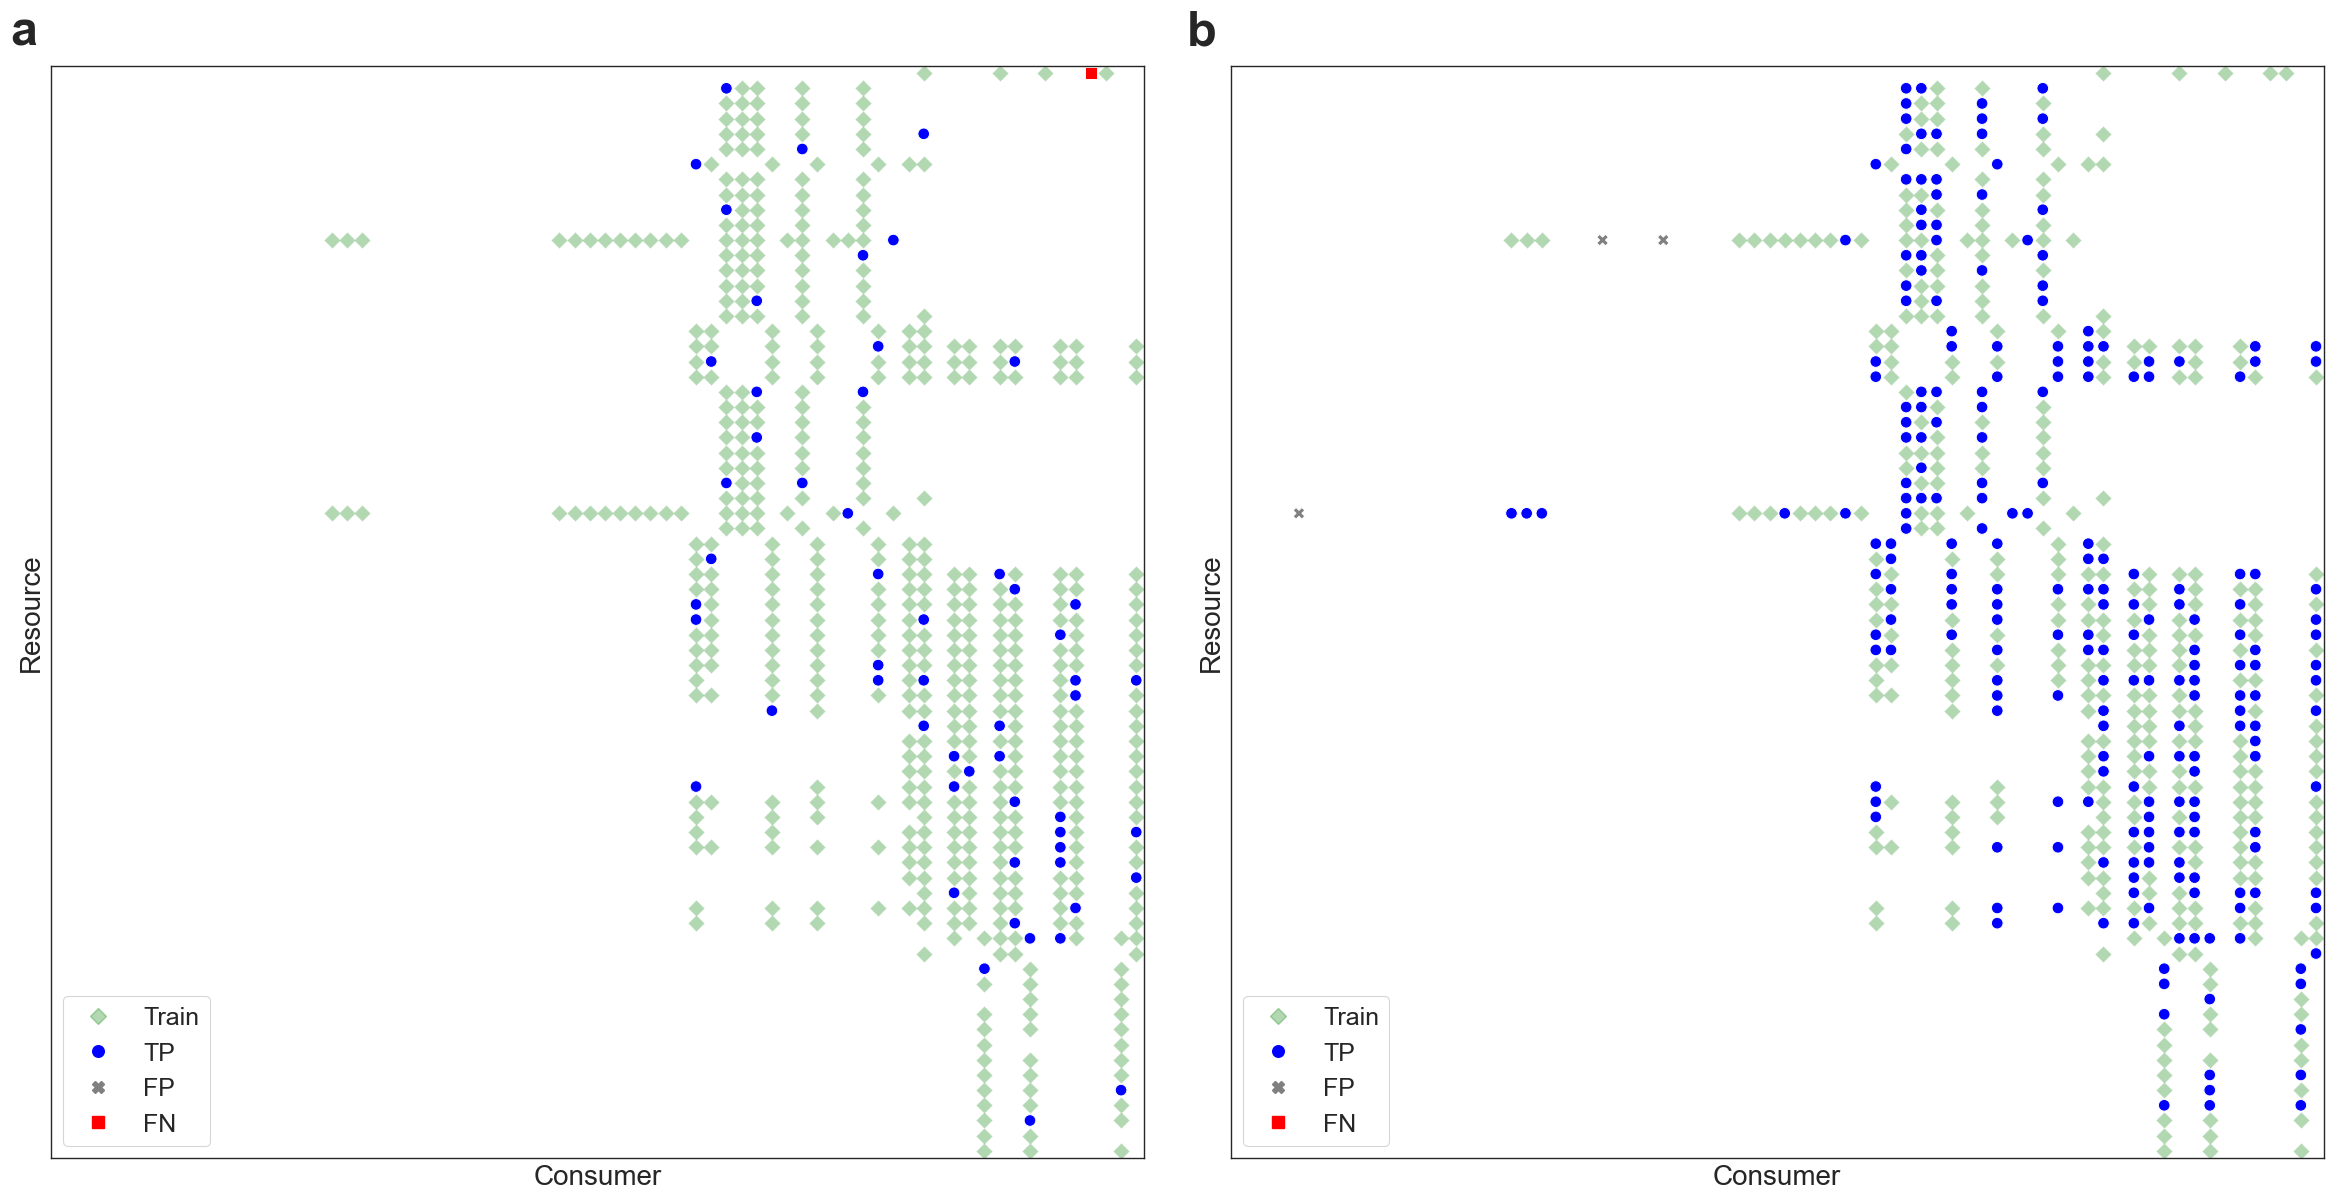

[SKIP] Scottish Lake: duplicate taxonomy labels make the snapshot node mapping ambiguous.
[SKIP] Grand Caricaie  marsh dominated by Schoenus nigricans, mown  Scmown1 : Food-web tax/mass MAT not found:
  /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/foodwebs_mat/Grand Caricaie  marsh dominated by Schoenus nigricans, mown  Scmown1_tax_mass.mat
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snapshot node names match tax_mass taxonomy.
[TOP50] 01/50 Bridge brook lake: ExperimentID=25, 90% TP/FP/FN=55/0/0, 60% TP/FP/FN=220/0/0
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snapshot node names match tax_mass taxonomy.
[TOP50] 02/50 Connera lake: ExperimentID=69, 90% TP/FP/FN=42/0/0, 60% TP/FP/FN=165/0/0
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snapshot node names match tax_mass taxonomy.
[TOP50] 03/50 Big hope lake: ExperimentID=40, 90% TP/FP/FN=33/0/0, 60% TP/FP/FN=129/0/0
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Snaps

{'__name__': '<run_path>',
 '__doc__': "Generate ranked Figure 2 options used by week-42.ipynb.\n\nThis file is executed with ``runpy.run_path(..., init_globals=globals())``\nfrom the notebook.  It deliberately reuses the notebook's validated data\nloaders and its existing plotting constants so the exported alternatives use\nthe same data semantics and visual style as the single-food-web panels.\n",
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__builtin__': <module 'builtins' (built-in)>,
 '__builtins__': <module 'builtins' (built-in)>,
 '_ih': ['',
  'import re\nfrom pathlib import Path\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport scipy.io\nimport seaborn as sns\nfrom matplotlib.lines import Line2D\nfrom scipy.sparse import csr_matrix, issparse\n\n\n# ============================================================\n# Style + repository\n# ============================================================\n\nsns.set_theme(context="paper", 

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.sparse import csr_matrix, issparse


# ============================================================
# Style + repository
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=3)


def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    for candidate in [start, *start.parents]:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        f"Could not locate repository root from {start}"
    )


REPO_ROOT = find_repo_root()


# ============================================================
# SIMPLE PANEL CONFIGURATION
# Edit foodweb, train_ratio and experiment_id per panel.
# train_ratio accepts 60 / 90 or 0.60 / 0.90.
# ============================================================

DEFAULT_FOODWEB = "Hoel lake"

PANELS = [
    {
        "letter": "a",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 90,
        "experiment_id": 1,
    },
    {
        "letter": "b",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 60,
        "experiment_id": 1,
    },
]

K_TARGET = 10
CLASSIFICATION_THRESHOLD = 0.50


# ============================================================
# Existing figure controls
# ============================================================

MIN_NODES = 40

SHOW_TITLES = False
SHOW_TICKS = False
USE_NUMERIC_AXIS_LABELS = False

XLAB = "Consumer"
YLAB = "Resource"

PANEL_XTICK_FONTSIZES = [12, 12]
PANEL_YTICK_FONTSIZES = [12, 12]

PRINT_SPECIES_KEY = False
EXPORT_SPECIES_KEY_FILE = True
SPECIES_KEY_FORMAT = "csv"

SPECIES_KEY_DIR = (
    REPO_ROOT
    / "docs/progress_notebooks_logs/2026/species_keys"
)


# ============================================================
# Input paths
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

PREDICTION_LOG_DIR = (
    RESULT_ROOT
    / "prediction_scores_logs"
)

ECOLOGICAL_SNAPSHOTS_DIR = (
    RESULT_ROOT
    / "ecological_snapshots"
)

BASE_MAT_PATH = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
)


# ============================================================
# Initial references
# Used only for the untouched initial configuration.
# Seeds are always read from the selected CSV row.
# ============================================================

def canonical_foodweb(name):
    name = str(name).strip()

    return (
        name[:-len("_tax_mass")]
        if name.endswith("_tax_mass")
        else name
    )


REFERENCE_FOODWEB = (
    "Grand Caricaie  marsh dominated by "
    "Cladietum marisci, not mown  ClControl2"
)


INITIAL_REFERENCE = {
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        60.0,
        21,
    ): {
        "seed": 1314098572,
        "TrainLinks": 460,
        "TestTP": 284,
        "TestFP": 8,
        "TestFN": 24,
    },
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        90.0,
        21,
    ): {
        "seed": 1316850472,
        "TrainLinks": 691,
        "TestTP": 39,
        "TestFP": 0,
        "TestFN": 38,
    },
}


# ============================================================
# Helpers
# ============================================================

def norm_name(value):
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def find_col(
    df,
    *aliases,
    required=True,
):
    lookup = {
        norm_name(column): column
        for column in df.columns
    }

    for alias in aliases:
        key = norm_name(alias)

        if key in lookup:
            return lookup[key]

    if required:
        raise KeyError(
            f"Missing required column. Tried {aliases}. "
            f"Available columns: {list(df.columns)}"
        )

    return None


def ratio_percent(value):
    value = float(value)

    if 0 < value <= 1:
        value *= 100

    if not 0 < value <= 100:
        raise ValueError(
            f"Invalid train_ratio={value!r}"
        )

    return float(value)


def tax_mass_stem(foodweb):
    foodweb = str(foodweb).strip()

    return (
        foodweb
        if foodweb.endswith("_tax_mass")
        else f"{foodweb}_tax_mass"
    )


def as_int(
    value,
    label,
):
    numeric = pd.to_numeric(
        pd.Series([value]),
        errors="coerce",
    ).iloc[0]

    if pd.isna(numeric):
        raise ValueError(
            f"{label} is not numeric: {value!r}"
        )

    integer = int(
        round(
            float(numeric)
        )
    )

    if not np.isclose(
        float(numeric),
        integer,
        atol=1e-9,
        rtol=0,
    ):
        raise ValueError(
            f"{label} is not an integer: {value!r}"
        )

    return integer


def binary_csr(matrix):
    if issparse(matrix):
        out = matrix.tocsr(
            copy=True
        )
    else:
        out = csr_matrix(
            np.asarray(matrix)
        )

    out.sum_duplicates()
    out.eliminate_zeros()

    if out.nnz:
        out.data = np.ones(
            out.nnz,
            dtype=np.int8,
        )

    return out.astype(
        np.int8
    )


def mask_and(
    a,
    b,
):
    out = a.multiply(
        b
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        out.data[:] = 1

    return out


def mask_and_not(
    a,
    b,
):
    out = (
        a.astype(np.int8)
        - a.multiply(b).astype(np.int8)
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        if np.any(
            out.data < 0
        ):
            raise ValueError(
                "Unexpected negative entries while "
                "reconstructing sparse masks."
            )

        out.data[:] = 1

    return out


def sparse_equal(
    a,
    b,
):
    if a.shape != b.shape:
        return False

    diff = (
        a.astype(np.int8)
        - b.astype(np.int8)
    ).tocsr()

    diff.eliminate_zeros()

    return (
        diff.nnz == 0
    )


def unwrap(value):
    while (
        isinstance(
            value,
            np.ndarray,
        )
        and value.size == 1
    ):
        value = value.reshape(
            -1
        )[0]

    return value


def matlab_str(value):
    value = unwrap(
        value
    )

    if isinstance(
        value,
        (bytes, np.bytes_),
    ):
        return bytes(
            value
        ).decode(
            "utf-8",
            errors="replace",
        ).strip()

    if isinstance(
        value,
        str,
    ):
        return value.strip()

    if isinstance(
        value,
        np.str_,
    ):
        return str(
            value
        ).strip()

    if (
        isinstance(
            value,
            np.ndarray,
        )
        and value.dtype.kind
        in {
            "U",
            "S",
        }
    ):
        parts = []

        for item in value.reshape(
            -1
        ):
            if isinstance(
                item,
                (bytes, np.bytes_),
            ):
                parts.append(
                    bytes(
                        item
                    ).decode(
                        "utf-8",
                        errors="replace",
                    )
                )

            else:
                parts.append(
                    str(
                        item
                    )
                )

        return "".join(
            parts
        ).strip()

    return str(
        value
    ).strip()


def matlab_str_list(value):
    return [
        matlab_str(
            item
        )
        for item
        in np.asarray(
            value,
            dtype=object,
        ).reshape(-1)
    ]


def struct_fields(obj):
    obj = unwrap(
        obj
    )

    if isinstance(
        obj,
        dict,
    ):
        return list(
            obj.items()
        )

    names = getattr(
        obj,
        "_fieldnames",
        None,
    )

    if names:
        return [
            (
                name,
                getattr(
                    obj,
                    name,
                ),
            )
            for name in names
        ]

    if (
        isinstance(
            obj,
            np.void,
        )
        and obj.dtype.names
    ):
        return [
            (
                name,
                obj[name],
            )
            for name
            in obj.dtype.names
        ]

    return []


def struct_get(
    obj,
    field,
):
    target = norm_name(
        field
    )

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) == target:
            return value

    raise KeyError(
        f"MATLAB struct is missing field "
        f"{field!r}. "
        f"Available fields: "
        f"{[name for name, _ in struct_fields(obj)]}"
    )


def struct_get_optional(
    obj,
    *aliases,
):
    targets = {
        norm_name(alias)
        for alias in aliases
    }

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) in targets:
            return value

    return None


# ============================================================
# Exact CSV row selection
# ============================================================

def select_run(panel):
    foodweb = panel[
        "foodweb"
    ]

    ratio = ratio_percent(
        panel[
            "train_ratio"
        ]
    )

    experiment_id = int(
        panel[
            "experiment_id"
        ]
    )

    csv_path = (
        PREDICTION_LOG_DIR
        / (
            f"{tax_mass_stem(foodweb)}"
            "_results_random_wlnm_dir_neg.csv"
        )
    )

    if not csv_path.is_file():
        raise FileNotFoundError(
            "Results CSV not found:\n"
            f"  {csv_path}"
        )

    df = pd.read_csv(
        csv_path
    )

    k_col = find_col(
        df,
        "K",
        "SubgraphK",
    )

    ratio_col = find_col(
        df,
        "TrainRatio",
        "TrainingRatio",
    )

    exp_col = find_col(
        df,
        "ExperimentID",
        "Experiment",
    )

    threshold_col = find_col(
        df,
        "Threshold",
        "ClassificationThreshold",
    )

    foodweb_col = find_col(
        df,
        "Foodweb",
        "FoodWebName",
        required=False,
    )

    k = pd.to_numeric(
        df[k_col],
        errors="coerce",
    )

    train_ratio = pd.to_numeric(
        df[ratio_col],
        errors="coerce",
    )

    train_ratio = np.where(
        train_ratio
        <= 1.0 + 1e-12,
        train_ratio * 100.0,
        train_ratio,
    )

    experiment = pd.to_numeric(
        df[exp_col],
        errors="coerce",
    )

    threshold = pd.to_numeric(
        df[threshold_col],
        errors="coerce",
    )

    mask = (
        np.isclose(
            k,
            K_TARGET,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            train_ratio,
            ratio,
            atol=1e-9,
            rtol=0,
        )
        & np.isclose(
            experiment,
            experiment_id,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            threshold,
            CLASSIFICATION_THRESHOLD,
            atol=1e-12,
            rtol=0,
        )
    )

    if (
        foodweb_col
        is not None
    ):
        mask &= (
            df[foodweb_col]
            .astype(str)
            .map(
                canonical_foodweb
            )
            .eq(
                canonical_foodweb(
                    foodweb
                )
            )
        )

    matches = df.loc[
        mask
    ]

    if len(
        matches
    ) != 1:
        raise ValueError(
            "Expected exactly one matching run, "
            f"but found {len(matches)}.\n"
            f"  foodweb={foodweb!r}\n"
            f"  K={K_TARGET}\n"
            f"  TrainRatio={ratio:g}%\n"
            f"  ExperimentID={experiment_id}\n"
            f"  threshold={CLASSIFICATION_THRESHOLD}\n"
            f"  CSV={csv_path}"
        )

    return (
        matches.iloc[0],
        csv_path,
        ratio,
    )


# ============================================================
# Resolve LOCAL snapshot by basename only
# ============================================================

def local_snapshot_from_row(row):
    row_df = pd.DataFrame(
        [row]
    )

    snapshot_col = find_col(
        row_df,
        "TrophicSnapshotFile",
        "SnapshotFile",
    )

    raw = row[
        snapshot_col
    ]

    if pd.isna(
        raw
    ):
        raise ValueError(
            "TrophicSnapshotFile is empty "
            "for the selected run."
        )

    snapshot_name = (
        str(raw)
        .strip()
        .replace(
            "\\",
            "/",
        )
        .split("/")[-1]
    )

    matches = [
        path
        for path
        in ECOLOGICAL_SNAPSHOTS_DIR.rglob(
            "*.mat"
        )
        if path.name
        == snapshot_name
    ]

    if len(
        matches
    ) != 1:
        raise FileNotFoundError(
            "Expected exactly one LOCAL "
            "ecological snapshot, "
            f"found {len(matches)}.\n"
            f"  basename={snapshot_name!r}\n"
            f"  searched under="
            f"{ECOLOGICAL_SNAPSHOTS_DIR}\n"
            f"  matches={matches}"
        )

    return matches[0]


# ============================================================
# Load tax/mass file
# ============================================================

def load_tax_mass(foodweb):
    mat_path = (
        BASE_MAT_PATH
        / (
            f"{tax_mass_stem(foodweb)}"
            ".mat"
        )
    )

    if not mat_path.is_file():
        raise FileNotFoundError(
            "Food-web tax/mass MAT "
            "not found:\n"
            f"  {mat_path}"
        )

    data = scipy.io.loadmat(
        mat_path,
        struct_as_record=False,
        squeeze_me=True,
        spmatrix=True,
    )

    for key in (
        "net",
        "taxonomy",
        "mass",
    ):
        if key not in data:
            raise KeyError(
                f"{mat_path} "
                f"is missing {key!r}"
            )

    net = binary_csr(
        data[
            "net"
        ]
    )
    # WLNM_dir_neg removes self-loops before saving empirical.
    net.setdiag(0)
    net.eliminate_zeros()

    taxonomy = matlab_str_list(
        data[
            "taxonomy"
        ]
    )

    mass = np.asarray(
        data[
            "mass"
        ]
    ).reshape(
        -1
    ).astype(
        float
    )

    n = len(
        taxonomy
    )

    if len(
        mass
    ) != n:
        raise ValueError(
            "taxonomy and mass "
            "have different lengths in "
            f"{mat_path}"
        )

    if net.shape != (
        n,
        n,
    ):
        raise ValueError(
            f"net.shape={net.shape}, "
            f"expected {(n, n)}"
        )

    if n < MIN_NODES:
        raise ValueError(
            f"Selected food web has "
            f"{n} nodes, below "
            f"MIN_NODES={MIN_NODES}."
        )

    if not np.all(
        np.isfinite(
            mass
        )
    ):
        raise ValueError(
            "Non-finite body masses "
            f"found in {mat_path}"
        )

    normalized = [
        re.sub(
            r"\s+",
            " ",
            value.strip(),
        )
        for value
        in taxonomy
    ]

    if len(
        set(
            normalized
        )
    ) != n:
        raise ValueError(
            "Duplicate taxonomy labels "
            "found; node mapping is ambiguous."
        )

    return (
        mat_path,
        net,
        taxonomy,
        mass,
    )


# ============================================================
# Load snapshot + reconstruct Train / TP / FP / FN
# ============================================================

def load_snapshot(
    snapshot_path,
    base_net,
    taxonomy,
):
    data = scipy.io.loadmat(
        snapshot_path,
        struct_as_record=False,
        squeeze_me=True,
        spmatrix=True,
    )

    if (
        "snapshot"
        not in data
    ):
        raise KeyError(
            "'snapshot' struct "
            "not found in "
            f"{snapshot_path}"
        )

    snapshot = data[
        "snapshot"
    ]

    empirical = binary_csr(
        struct_get(
            snapshot,
            "empirical",
        )
    )

    train = binary_csr(
        struct_get(
            snapshot,
            "train",
        )
    )

    pseudo = binary_csr(
        struct_get(
            snapshot,
            "pseudo",
        )
    )

    metadata = struct_get(
        snapshot,
        "metadata",
    )

    n = len(
        taxonomy
    )

    for name, matrix in {
        "empirical": empirical,
        "train": train,
        "pseudo": pseudo,
    }.items():

        if matrix.shape != (
            n,
            n,
        ):
            raise ValueError(
                f"snapshot.{name}.shape="
                f"{matrix.shape}, "
                f"expected {(n, n)}"
            )

    # Validate snapshot node indexing and direction against
    # the original directed food-web matrix.
    if not sparse_equal(
        empirical,
        base_net,
    ):
        if sparse_equal(
            empirical,
            base_net.T.tocsr(),
        ):
            raise ValueError(
                "snapshot.empirical matches "
                "net.T rather than net. "
                "Direction/index convention "
                "is inconsistent."
            )

        raise ValueError(
            "snapshot.empirical does not "
            "match the tax_mass net. "
            "Node identity/order cannot "
            "be validated safely."
        )

    train_outside_empirical = (
        mask_and_not(
            train,
            empirical,
        )
    )

    if (
        train_outside_empirical.nnz
    ):
        raise ValueError(
            "snapshot.train contains "
            f"{train_outside_empirical.nnz} "
            "links absent from empirical."
        )

    # If metadata exposes node names, verify those explicitly too.
    metadata_nodes = struct_get_optional(
        metadata,
        "taxonomy",
        "taxa",
        "species",
        "species_names",
        "node_names",
        "node_labels",
    )

    if (
        metadata_nodes
        is not None
    ):
        names = matlab_str_list(
            metadata_nodes
        )

        if len(
            names
        ) == n:

            def clean(value):
                return re.sub(
                    r"\s+",
                    " ",
                    value.strip(),
                )

            if (
                list(
                    map(
                        clean,
                        names,
                    )
                )
                != list(
                    map(
                        clean,
                        taxonomy,
                    )
                )
            ):
                raise ValueError(
                    "Snapshot metadata node names "
                    "do not match tax_mass taxonomy "
                    "in the same index order."
                )

            print(
                "[INFO] Snapshot node names "
                "match tax_mass taxonomy."
            )

    # --------------------------------------------------------
    # Required reconstruction
    # --------------------------------------------------------
    #
    # Train          = train
    # true_test      = empirical & ~train
    # predicted_test = pseudo & ~train
    # TP             = true_test & predicted_test
    # FP             = predicted_test & ~true_test
    # FN             = true_test & ~predicted_test
    #

    true_test = mask_and_not(
        empirical,
        train,
    )

    predicted_test = mask_and_not(
        pseudo,
        train,
    )

    tp = mask_and(
        true_test,
        predicted_test,
    )

    fp = mask_and_not(
        predicted_test,
        true_test,
    )

    fn = mask_and_not(
        true_test,
        predicted_test,
    )

    return {
        "Train": train,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "metadata": metadata,
    }


# ============================================================
# Validate seed + reconstructed counts against selected CSV row
# ============================================================

def validate_run(
    row,
    panel,
    ratio,
    masks,
    snapshot_path,
):
    row_df = pd.DataFrame(
        [row]
    )

    seed_col = find_col(
        row_df,
        "Seed",
        "RandomSeed",
        "ExperimentSeed",
    )

    train_col = find_col(
        row_df,
        "TrainLinks",
    )

    tp_col = find_col(
        row_df,
        "TestTP",
    )

    fp_col = find_col(
        row_df,
        "TestFP",
    )

    fn_col = find_col(
        row_df,
        "TestFN",
    )

    seed = as_int(
        row[
            seed_col
        ],
        "Seed",
    )

    csv_counts = {
        "TrainLinks": as_int(
            row[
                train_col
            ],
            "TrainLinks",
        ),
        "TestTP": as_int(
            row[
                tp_col
            ],
            "TestTP",
        ),
        "TestFP": as_int(
            row[
                fp_col
            ],
            "TestFP",
        ),
        "TestFN": as_int(
            row[
                fn_col
            ],
            "TestFN",
        ),
    }

    reconstructed = {
        "TrainLinks": (
            masks[
                "Train"
            ].nnz
        ),
        "TestTP": (
            masks[
                "TP"
            ].nnz
        ),
        "TestFP": (
            masks[
                "FP"
            ].nnz
        ),
        "TestFN": (
            masks[
                "FN"
            ].nnz
        ),
    }

    if (
        csv_counts
        != reconstructed
    ):
        raise ValueError(
            "Reconstructed counts do not "
            "match the selected CSV row.\n"
            f"  CSV={csv_counts}\n"
            f"  reconstructed={reconstructed}\n"
            f"  snapshot={snapshot_path}"
        )

    # If metadata contains its own seed, verify that too.
    metadata_seed = struct_get_optional(
        masks[
            "metadata"
        ],
        "seed",
        "random_seed",
        "experiment_seed",
    )

    if (
        metadata_seed
        is not None
    ):
        snapshot_seed = as_int(
            unwrap(
                metadata_seed
            ),
            "snapshot metadata seed",
        )

        if (
            snapshot_seed
            != seed
        ):
            raise ValueError(
                "Seed mismatch between CSV "
                "and snapshot metadata:\n"
                f"  CSV={seed}\n"
                f"  snapshot={snapshot_seed}"
            )

    # Only the untouched initial configuration is checked
    # against the supplied reference seed/counts.
    ref_key = (
        canonical_foodweb(
            panel[
                "foodweb"
            ]
        ),
        float(
            ratio
        ),
        int(
            panel[
                "experiment_id"
            ]
        ),
    )

    reference = INITIAL_REFERENCE.get(
        ref_key
    )

    if (
        reference
        is not None
    ):
        if (
            seed
            != reference[
                "seed"
            ]
        ):
            raise ValueError(
                "Initial seed does not match "
                "the supplied reference:\n"
                f"  expected="
                f"{reference['seed']}\n"
                f"  CSV={seed}"
            )

        for key in (
            "TrainLinks",
            "TestTP",
            "TestFP",
            "TestFN",
        ):
            if (
                reconstructed[
                    key
                ]
                != reference[
                    key
                ]
            ):
                raise ValueError(
                    "Initial reference mismatch "
                    f"for {key}: "
                    f"expected={reference[key]}, "
                    f"observed={reconstructed[key]}"
                )

    return (
        seed,
        reconstructed,
    )


# ============================================================
# Sparse directed links -> mass-sorted plotting coordinates
#
# Matrix convention:
#   row    = Resource / Prey
#   column = Consumer / Predator
# ============================================================

def mask_to_df(
    mask,
    original_to_sorted,
    label,
):
    (
        resource_idx,
        consumer_idx,
    ) = mask.nonzero()

    return pd.DataFrame({
        "PreyIdx": (
            original_to_sorted[
                resource_idx
            ]
        ),
        "PredIdx": (
            original_to_sorted[
                consumer_idx
            ]
        ),
        "Label": label,
    })


# ============================================================
# Validate ALL panels before drawing
# ============================================================

for label, path in {
    "prediction_scores_logs":
        PREDICTION_LOG_DIR,
    "ecological_snapshots":
        ECOLOGICAL_SNAPSHOTS_DIR,
    "foodwebs_mat":
        BASE_MAT_PATH,
}.items():

    if not path.is_dir():
        raise FileNotFoundError(
            f"Missing {label} directory:\n"
            f"  {path}"
        )


prepared = []
tax_mass_cache = {}
species_key_done = set()


for panel_idx, panel in enumerate(
    PANELS
):
    letter = panel.get(
        "letter",
        chr(
            ord("a")
            + panel_idx
        ),
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"[INFO] Panel {letter}: "
        f"{canonical_foodweb(panel['foodweb'])}"
    )

    # --------------------------------------------------------
    # 1. Locate exactly one run in prediction_scores_logs
    # --------------------------------------------------------

    (
        row,
        results_csv,
        ratio,
    ) = select_run(
        panel
    )

    # --------------------------------------------------------
    # 2. Resolve LOCAL snapshot from TrophicSnapshotFile basename
    # --------------------------------------------------------

    snapshot_path = (
        local_snapshot_from_row(
            row
        )
    )

    # --------------------------------------------------------
    # 3. Load taxonomy / mass / empirical net
    # --------------------------------------------------------

    stem = tax_mass_stem(
        panel[
            "foodweb"
        ]
    )

    if (
        stem
        not in tax_mass_cache
    ):
        tax_mass_cache[
            stem
        ] = load_tax_mass(
            panel[
                "foodweb"
            ]
        )

    (
        tax_mass_path,
        base_net,
        taxonomy,
        mass,
    ) = tax_mass_cache[
        stem
    ]

    # --------------------------------------------------------
    # 4. Load snapshot and reconstruct Train / TP / FP / FN
    # --------------------------------------------------------

    masks = load_snapshot(
        snapshot_path,
        base_net,
        taxonomy,
    )

    # --------------------------------------------------------
    # 5. Validate seed and reconstructed counts
    # --------------------------------------------------------

    (
        seed,
        counts,
    ) = validate_run(
        row=row,
        panel=panel,
        ratio=ratio,
        masks=masks,
        snapshot_path=snapshot_path,
    )

    print(
        "[INFO] Exact run validated:\n"
        f"  K={K_TARGET}, "
        f"TrainRatio={ratio:g}%, "
        f"ExperimentID="
        f"{panel['experiment_id']}, "
        f"threshold="
        f"{CLASSIFICATION_THRESHOLD:.2f}\n"
        f"  Seed={seed}\n"
        f"  Train="
        f"{counts['TrainLinks']:,}, "
        f"TP={counts['TestTP']:,}, "
        f"FP={counts['TestFP']:,}, "
        f"FN={counts['TestFN']:,}\n"
        f"  CSV={results_csv}\n"
        f"  Snapshot={snapshot_path}"
    )

    # --------------------------------------------------------
    # 6. Sort species by body mass
    # --------------------------------------------------------

    # Same conversion used by the original cell.
    mass_mg = np.round(
        mass * 1000.0,
        4,
    )

    sorted_original_idx = np.argsort(
        mass_mg,
        kind="stable",
    )

    sorted_species = [
        taxonomy[
            index
        ]
        for index
        in sorted_original_idx
    ]

    sorted_mass_mg = (
        mass_mg[
            sorted_original_idx
        ]
    )

    n = len(
        sorted_species
    )

    original_to_sorted = np.empty(
        n,
        dtype=int,
    )

    original_to_sorted[
        sorted_original_idx
    ] = np.arange(
        n
    )

    # Stable numbering for the same food web in both panels.
    species_to_num = {
        species: index + 1
        for index, species
        in enumerate(
            sorted_species
        )
    }

    # --------------------------------------------------------
    # Optional species key
    # --------------------------------------------------------

    if (
        PRINT_SPECIES_KEY
        and stem
        not in species_key_done
    ):
        key_df = pd.DataFrame({
            "Number": np.arange(
                1,
                n + 1,
            ),
            "Species":
                sorted_species,
            "Mass_mg":
                sorted_mass_mg,
        })

        key_df[
            "Mass_mg"
        ] = (
            key_df[
                "Mass_mg"
            ]
            .map(
                lambda value:
                f"{value:.4f}"
            )
        )

        print(
            "\n"
            + key_df.to_string(
                index=False
            )
        )

        if (
            EXPORT_SPECIES_KEY_FILE
        ):
            SPECIES_KEY_DIR.mkdir(
                parents=True,
                exist_ok=True,
            )

            safe_foodweb = re.sub(
                r"[^A-Za-z0-9._-]+",
                "_",
                stem,
            ).strip(
                "_"
            )

            extension = (
                "tsv"
                if (
                    SPECIES_KEY_FORMAT.lower()
                    == "tsv"
                )
                else "csv"
            )

            output_path = (
                SPECIES_KEY_DIR
                / (
                    f"{safe_foodweb}_"
                    f"species_key."
                    f"{extension}"
                )
            )

            key_df.to_csv(
                output_path,
                sep=(
                    "\t"
                    if extension
                    == "tsv"
                    else ","
                ),
                index=False,
                encoding="utf-8",
            )

            print(
                "[INFO] Saved species key: "
                f"{output_path.resolve()}"
            )

        species_key_done.add(
            stem
        )

    # --------------------------------------------------------
    # 7. Convert reconstructed matrices to plot coordinates
    # --------------------------------------------------------

    df_train = mask_to_df(
        masks[
            "Train"
        ],
        original_to_sorted,
        "Train",
    )

    df_pm = pd.concat(
        [
            mask_to_df(
                masks[
                    "TP"
                ],
                original_to_sorted,
                "TP",
            ),
            mask_to_df(
                masks[
                    "FP"
                ],
                original_to_sorted,
                "FP",
            ),
            mask_to_df(
                masks[
                    "FN"
                ],
                original_to_sorted,
                "FN",
            ),
        ],
        ignore_index=True,
    )

    prepared.append({
        "letter":
            letter,
        "foodweb":
            canonical_foodweb(
                panel[
                    "foodweb"
                ]
            ),
        "train_ratio":
            ratio,
        "experiment_id":
            int(
                panel[
                    "experiment_id"
                ]
            ),
        "seed":
            seed,
        "n":
            n,
        "sorted_species":
            sorted_species,
        "species_to_num":
            species_to_num,
        "df_train":
            df_train,
        "df_pm":
            df_pm,
    })


# ============================================================
# Plot only AFTER every panel has passed all checks
# ============================================================

fig, axs = plt.subplots(
    1,
    len(
        prepared
    ),
    figsize=(
        12 * len(
            prepared
        ),
        12,
    ),
    squeeze=False,
)

axs = axs.ravel()


# Keep Train / TP / FP / FN in every legend,
# including FP when FP=0 in panel b.
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="None",
        markerfacecolor="green",
        markeredgecolor="green",
        alpha=0.3,
        markersize=np.sqrt(
            70
        ),
        label="Train",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="blue",
        markeredgecolor="blue",
        markersize=np.sqrt(
            70
        ),
        label="TP",
    ),
    Line2D(
        [0],
        [0],
        marker="X",
        linestyle="None",
        markerfacecolor="gray",
        markeredgecolor="gray",
        markersize=np.sqrt(
            70
        ),
        label="FP",
    ),
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=np.sqrt(
            70
        ),
        label="FN",
    ),
]


for panel_idx, panel in enumerate(
    prepared
):
    ax = axs[
        panel_idx
    ]

    n = panel[
        "n"
    ]

    # --------------------------------------------------------
    # Training links first
    # green diamond, alpha=0.3, s=70
    # --------------------------------------------------------

    if not panel[
        "df_train"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_train"
            ],
            x="PredIdx",
            y="PreyIdx",
            color="green",
            marker="D",
            alpha=0.3,
            s=70,
            legend=False,
            ax=ax,
        )

    # --------------------------------------------------------
    # TP / FP / FN
    # --------------------------------------------------------

    if not panel[
        "df_pm"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_pm"
            ],
            x="PredIdx",
            y="PreyIdx",
            hue="Label",
            style="Label",
            hue_order=[
                "TP",
                "FP",
                "FN",
            ],
            style_order=[
                "TP",
                "FP",
                "FN",
            ],
            markers={
                "TP": "o",
                "FP": "X",
                "FN": "s",
            },
            palette={
                "TP": "blue",
                "FP": "gray",
                "FN": "red",
            },
            s=70,
            legend=False,
            ax=ax,
        )

    # Consumer body mass increases left -> right.
    ax.set_xlim(
        -0.5,
        n - 0.5,
    )

    # Resource body mass increases top -> bottom.
    ax.set_ylim(
        n - 0.5,
        -0.5,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlabel(
        XLAB,
        fontsize=20,
    )

    ax.set_ylabel(
        YLAB,
        fontsize=20,
    )

    # --------------------------------------------------------
    # Existing tick controls
    # --------------------------------------------------------

    if SHOW_TICKS:
        ax.set_xticks(
            range(
                n
            )
        )

        ax.set_yticks(
            range(
                n
            )
        )

        x_fontsize = (
            PANEL_XTICK_FONTSIZES[
                panel_idx
            ]
        )

        y_fontsize = (
            PANEL_YTICK_FONTSIZES[
                panel_idx
            ]
        )

        if (
            USE_NUMERIC_AXIS_LABELS
        ):
            labels = [
                str(
                    panel[
                        "species_to_num"
                    ][
                        species
                    ]
                )
                for species
                in panel[
                    "sorted_species"
                ]
            ]

            ax.set_xticklabels(
                labels,
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                labels,
                fontsize=y_fontsize,
            )

        else:
            ax.set_xticklabels(
                panel[
                    "sorted_species"
                ],
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                panel[
                    "sorted_species"
                ],
                fontsize=y_fontsize,
            )

        ax.tick_params(
            axis="both",
            which="both",
            length=3,
        )

    else:
        ax.set_xticks(
            []
        )

        ax.set_yticks(
            []
        )

        ax.set_xticklabels(
            []
        )

        ax.set_yticklabels(
            []
        )

        ax.tick_params(
            axis="both",
            which="both",
            length=0,
        )

    # --------------------------------------------------------
    # Existing title control
    # --------------------------------------------------------

    if SHOW_TITLES:
        ax.set_title(
            panel[
                "foodweb"
            ],
            fontsize=12,
        )

    # --------------------------------------------------------
    # Panel letter outside matrix
    # --------------------------------------------------------

    ax.annotate(
        panel["letter"],
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(-10, 8),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=35,
        fontweight="bold",
        annotation_clip=False,
    )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        handles=legend_handles,
        loc="lower left",
        prop={
            "size": 18,
        },
        title="",
    )


plt.tight_layout()
plt.show()


# Generate alternatives with the fewest FN + FP across both panels.
import runpy

FIGURE_OUTPUT_FORMAT = "pdf"
BEST_RUN_GENERATOR_GLOBALS = globals().copy()
BEST_RUN_GENERATOR_GLOBALS["FIGURE_SELECTION_MODE"] = "lowest_fn_fp"
BEST_RUN_GENERATOR_GLOBALS["FIGURE_NUM_OPTIONS"] = 50

runpy.run_path(
    REPO_ROOT / 'docs/stats/generate_week42_figure2_top20.py',
    init_globals=BEST_RUN_GENERATOR_GLOBALS,
)

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Loading and validating the four result sets...
[PASS] Matched 290/290 food webs; 1,160 method-level rows and 5,800 plotting observations.

=== Input and protocol audit ===


,Method,Source,Food webs,Raw runs,Runs/web,Aggregation,Test negatives:positives,Target train ratio,Achieved ratio recorded,Threshold,Notes
0,WLNM original,result_wlnm_original_100x290_train10-90_thresh...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
1,WLNM directed-negative,result_wlnm_dir_neg_roleonly_trophicv2_100x290...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
2,SEAL original,src/python/data/result/prediction_scores_logs,290,580,2,Mean across repeats,1:1,90%,50.00–94.74% (median 90.23%),0.50,Balanced held-out positives/negatives
3,SEAL directed,src/python/seal_directed/data/result_seal_dire...,290,2900,10,Mean across repeats,1:1,90%,90.00–94.74% (median 90.13%),0.50,Balanced held-out positives/negatives; role-po...



=== WLNM raw-run counts for the five common metrics ===


,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns,Method
0,ROC-AUC,290,100,100.0,100,WLNM original
1,PR-AUC,290,100,100.0,100,WLNM original
2,F1,290,100,100.0,100,WLNM original
3,Precision,290,100,100.0,100,WLNM original
4,Recall,290,100,100.0,100,WLNM original
5,ROC-AUC,290,100,100.0,100,WLNM directed-negative
6,PR-AUC,290,100,100.0,100,WLNM directed-negative
7,F1,290,100,100.0,100,WLNM directed-negative
8,Precision,290,100,100.0,100,WLNM directed-negative
9,Recall,290,100,100.0,100,WLNM directed-negative



=== Food-web-level descriptive medians ===


Method,WLNM original,WLNM directed-negative,SEAL original,SEAL directed
Metric,,,,
ROC-AUC,0.8306,0.9102,0.8474,0.9148
PR-AUC,0.6032,0.5475,0.8326,0.9153
F1,0.6591,0.7201,0.7719,0.8396
Precision,0.7180,0.9507,0.7230,0.8335
Recall,0.6372,0.6079,0.8472,0.8556



[CAUTION] Preliminary descriptive comparison only. SEAL uses 2/10 repeats and a 1:1 held-out negative:positive ratio; WLNM uses all 100 raw repeats and a 2:1 ratio. PR-AUC, Precision and F1 are especially sensitive to this prevalence difference.
[CAUTION] 'SEAL directed' is the complete current configuration (directionality, node attributes and role-aware negative sampling), not a direction-only ablation.

[PASS] Generated 20 boxplots (4 methods × 5 metrics).


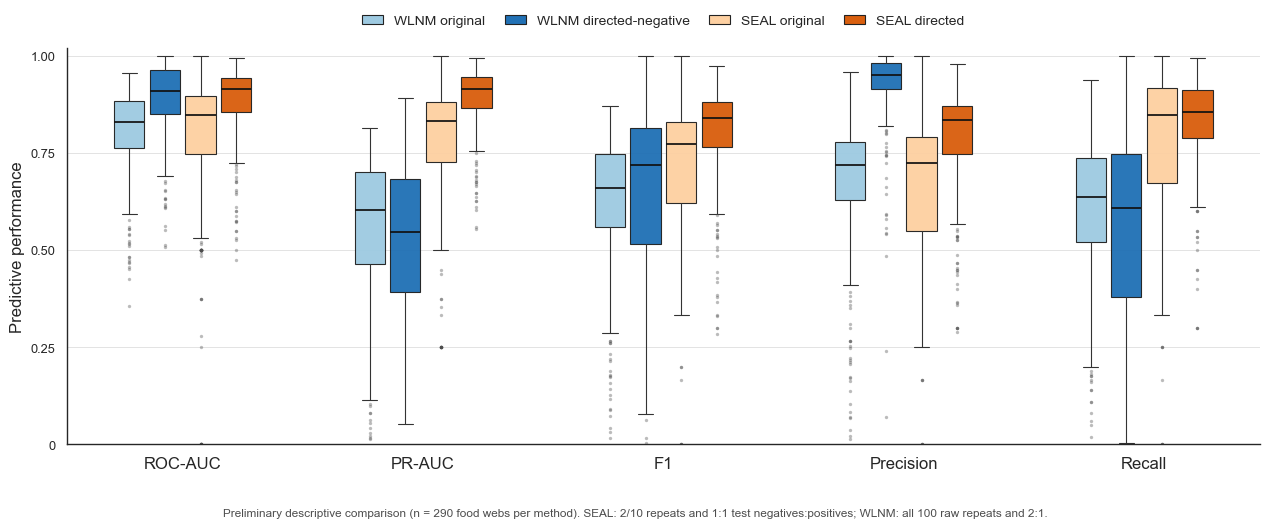

In [2]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Configuration
# ============================================================

def find_repo_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(f"Repository root not found from {start}")


REPO_ROOT = find_repo_root(Path.cwd())
TRAIN_RATIO = 90
THRESHOLD = 0.50
N_WEBS = 290
WLNM_RUNS = 100
MIN_RETAINED = 25
RETENTION = "tukey_iqr_1p5_min25runs_threshold0p50_v1"

WLNM_ROOTS = {
    "WLNM_original": REPO_ROOT / "src/matlab/data/result_wlnm_original_100x290_train10-90_thresh0p50_Apocrita_20260916_221905",
    "WLNM_dir_neg": REPO_ROOT / "src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848",
}
SEAL_DIRECTED_10X_ROOT = REPO_ROOT / "src/python/seal_directed/data/result_seal_directed_10x290_220d0a21_20261014"
SEAL_CONFIG = {
    "SEAL_original": {
        "results": REPO_ROOT / "src/python/data/result/prediction_scores_logs",
        "logs": REPO_ROOT / "src/python/data/result/terminal_logs",
        "pattern": "*_results_SEAL.csv",
        "version": "SEAL_undirected",
        "repeats": 2,
        "seeds": {12345, 12346},
        "fallbacks": 0,
    },
    "SEAL_directed": {
        "results": SEAL_DIRECTED_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_DIRECTED_10X_ROOT / "task_logs",
        "validation": SEAL_DIRECTED_10X_ROOT / "summary/RUN_VALIDATION.json",
        "pattern": "*_results_SEAL_directed.csv",
        "version": "SEAL_directed",
        "repeats": 10,
        "seeds": set(range(12345, 12345 + N_WEBS * 10)),
        "fallbacks": 80,
    },
}
METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
]
METRICS = [x for x, _ in METRIC_SPECS]
METRIC_LABELS = dict(METRIC_SPECS)
METHOD_ORDER = ["WLNM_original", "WLNM_dir_neg", "SEAL_original", "SEAL_directed"]
METHOD_LABELS = {
    "WLNM_original": "WLNM original",
    "WLNM_dir_neg": "WLNM directed-negative",
    "SEAL_original": "SEAL original",
    "SEAL_directed": "SEAL directed",
}
PALETTE = {
    "WLNM_original": "#9ECAE1",
    "WLNM_dir_neg": "#2171B5",
    "SEAL_original": "#FDD0A2",
    "SEAL_directed": "#D95F0E",
}


# ============================================================
# Loaders and validation
# ============================================================

def fw_key(value):
    text = Path(str(value)).stem.strip()
    text = re.sub(r"_tax_mass_results_SEAL(?:_directed)?$", "", text, flags=re.I)
    text = re.sub(r"_tax_mass_results_random_wlnm_(?:original|dir_neg)$", "", text, flags=re.I)
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text.casefold()).split())


def validate_values(frame, label):
    values = frame[METRICS].apply(pd.to_numeric, errors="coerce")
    if values.isna().any().any():
        raise ValueError(f"{label}: missing or non-numeric metric values")
    array = values.to_numpy(float)
    if not np.isfinite(array).all() or ((array < 0) | (array > 1)).any():
        raise ValueError(f"{label}: metric values must be finite and within [0, 1]")


def validate_keys(frame, source_col, label):
    collisions = (
        frame[["FW_KEY", source_col]].drop_duplicates()
        .groupby("FW_KEY")[source_col].nunique()
    )
    if (collisions > 1).any():
        raise ValueError(f"{label}: normalized food-web name collision")
    if frame["FW_KEY"].nunique() != N_WEBS:
        raise ValueError(f"{label}: expected {N_WEBS} food webs")


def validate_wlnm_raw(root):
    files = sorted((root / "prediction_scores_logs").glob("*.csv"))
    if len(files) != N_WEBS:
        raise ValueError(f"{root.name}: expected {N_WEBS} raw CSV files")
    ratios = []
    total_rows = 0
    usecols = ["TrainRatio", "TestTP", "TestFP", "TestFN", "TestTN"]
    for path in files:
        data = pd.read_csv(path, usecols=usecols)
        data = data[np.isclose(data["TrainRatio"], TRAIN_RATIO)]
        if len(data) != WLNM_RUNS:
            raise ValueError(f"{path.name}: expected {WLNM_RUNS} train-90 runs")
        positives = data["TestTP"] + data["TestFN"]
        negatives = data["TestFP"] + data["TestTN"]
        if (positives <= 0).any():
            raise ValueError(f"{path.name}: invalid test-positive count")
        ratios.extend((negatives / positives).to_numpy(float))
        total_rows += len(data)
    ratios = np.asarray(ratios)
    if not np.allclose(ratios, 2.0):
        raise ValueError(f"{root.name}: test negative:positive ratio is not 2:1")
    return total_rows


def load_wlnm(method):
    root = WLNM_ROOTS[method]
    data = load_raw_predictive_compat(
        root,
        method,
        METRIC_SPECS,
        WLNM_RUNS,
        WLNM_RUNS,
        train_ratios=[TRAIN_RATIO],
    )
    data["FW_KEY"] = data["Foodweb"].map(fw_key)
    validate_keys(data, "Foodweb", method)
    if data.duplicated(["FW_KEY", "Metric"]).any():
        raise ValueError(f"{method}: duplicate food-web/metric rows")
    wide = (
        data.pivot(
            index="FW_KEY",
            columns="Metric",
            values="MeanAfterTukey",
        )
        .rename_axis(None, axis=1)
        .reset_index()
    )
    validate_values(wide, method)
    wide["Method"] = method
    raw_rows = validate_wlnm_raw(root)
    retention = data.groupby("Metric", as_index=False).agg(
        FoodWebs=("FW_KEY", "nunique"),
        MinimumRetainedRuns=("RetainedRunsAfterTukey", "min"),
        MedianRetainedRuns=("RetainedRunsAfterTukey", "median"),
        MaximumRetainedRuns=("RetainedRunsAfterTukey", "max"),
    )
    retention["Method"] = METHOD_LABELS[method]
    retention["Metric"] = retention["Metric"].map(METRIC_LABELS)
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": root.name,
        "Food webs": N_WEBS,
        "Raw runs": raw_rows,
        "Runs/web": "100",
        "Aggregation": "Mean across all raw runs; no Tukey filtering",
        "Test negatives:positives": "2:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": "90% label",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": "All 100 raw runs included",
    }
    return wide, audit, retention

def load_seal(method, config):
    validation = None
    if validation_path := config.get("validation"):
        validation = json.loads(validation_path.read_text())
        expected_validation = {
            "status": "VALIDATION_OK",
            "experiments": config["repeats"],
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * config["repeats"],
            "validated_runs": N_WEBS * config["repeats"],
            "unique_seeds": N_WEBS * config["repeats"],
            "fallback_runs": config["fallbacks"],
        }
        observed_validation = {
            key: validation.get(key) for key in expected_validation
        }
        if observed_validation != expected_validation:
            raise ValueError(
                f"{method}: unexpected campaign validation summary: "
                f"{observed_validation}"
            )
    files = sorted(config["results"].glob(config["pattern"]))
    if len(files) != N_WEBS:
        raise ValueError(f"{method}: expected {N_WEBS} result CSVs, found {len(files)}")
    frames = []
    required = set(METRICS) | {"Version", "TrainRatio", "ExperimentID", "Seed", "Threshold"}
    if validation is not None:
        required.add("Device")
    for path in files:
        data = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        if missing := required.difference(data.columns):
            raise ValueError(f"{path.name}: missing {sorted(missing)}")
        source_foodweb = re.sub(
            r"_tax_mass_results_SEAL(?:_directed)?\.csv$",
            "",
            path.name,
            flags=re.I,
        )
        data = data.assign(
            SourceFoodweb=source_foodweb,
            FW_KEY=fw_key(source_foodweb),
        )
        frames.append(data)
    raw = pd.concat(frames, ignore_index=True)
    validate_keys(raw, "SourceFoodweb", method)
    if validation is not None:
        if "Device" not in raw or set(raw["Device"].unique()) != {"cuda:0"}:
            raise ValueError(f"{method}: expected every validated run to use cuda:0")
    if set(raw["Version"].unique()) != {config["version"]}:
        raise ValueError(f"{method}: unexpected Version")
    if not np.allclose(raw["Threshold"], THRESHOLD):
        raise ValueError(f"{method}: unexpected threshold")
    if set(raw["Seed"].astype(int)) != config["seeds"] or set(raw["ExperimentID"].astype(int)) != set(range(1, config["repeats"] + 1)):
        raise ValueError(f"{method}: unexpected seeds or ExperimentID values")
    if set(raw.groupby("FW_KEY").size()) != {config["repeats"]}:
        raise ValueError(f"{method}: unexpected repeats per food web")
    if raw.duplicated(["FW_KEY", "ExperimentID"]).any():
        raise ValueError(f"{method}: duplicate food-web/experiment rows")
    validate_values(raw, method)

    log_files = sorted(config["logs"].rglob("*.log"))
    if len(log_files) != len(raw):
        raise ValueError(f"{method}: expected {len(raw)} terminal logs, found {len(log_files)}")
    fallback_text = "role-constrained negative pool too small; falling back to all directed unknown links"
    fallbacks = sum(fallback_text in path.read_text(errors="replace") for path in log_files)
    if fallbacks != config["fallbacks"]:
        raise ValueError(f"{method}: expected {config['fallbacks']} fallbacks, found {fallbacks}")

    wide = raw.groupby("FW_KEY", as_index=False)[METRICS].mean()
    validate_values(wide, f"{method} means")
    wide["Method"] = method
    ratio_min, ratio_median, ratio_max = raw.TrainRatio.min(), raw.TrainRatio.median(), raw.TrainRatio.max()
    note = "Balanced held-out positives/negatives"
    if method == "SEAL_directed":
        note += f"; role-pool fallback in {fallbacks}/{len(raw)} runs"
        if validation is not None:
            note += "; CUDA campaign VALIDATION_OK"
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": str(config["results"].relative_to(REPO_ROOT)),
        "Food webs": N_WEBS,
        "Raw runs": len(raw),
        "Runs/web": str(config["repeats"]),
        "Aggregation": "Mean across repeats",
        "Test negatives:positives": "1:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": f"{ratio_min:.2f}–{ratio_max:.2f}% (median {ratio_median:.2f}%)",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": note,
    }
    return wide, audit


# ============================================================
# Build the matched comparison table
# ============================================================

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Loading and validating the four result sets...")

wlnm_original, audit_wo, retention_wo = load_wlnm("WLNM_original")
wlnm_dir_neg, audit_wd, retention_wd = load_wlnm("WLNM_dir_neg")
seal_original, audit_so = load_seal("SEAL_original", SEAL_CONFIG["SEAL_original"])
seal_directed, audit_sd = load_seal("SEAL_directed", SEAL_CONFIG["SEAL_directed"])
frames = {
    "WLNM_original": wlnm_original,
    "WLNM_dir_neg": wlnm_dir_neg,
    "SEAL_original": seal_original,
    "SEAL_directed": seal_directed,
}
key_sets = {method: set(frame.FW_KEY) for method, frame in frames.items()}
common = set.intersection(*key_sets.values())
union = set.union(*key_sets.values())
if len(common) != N_WEBS or len(union) != N_WEBS:
    details = {method: {"missing": sorted(union - keys)[:10], "unpaired": sorted(keys - common)[:10]} for method, keys in key_sets.items()}
    raise ValueError(f"Food-web matching failed: {details}")

comparison_wide = pd.concat([frames[m] for m in METHOD_ORDER], ignore_index=True)[["FW_KEY", "Method", *METRICS]]
if comparison_wide.shape != (1160, 7) or comparison_wide.duplicated(["FW_KEY", "Method"]).any():
    raise ValueError(f"Invalid wide table: shape={comparison_wide.shape}")
validate_values(comparison_wide, "combined comparison")
comparison_long = comparison_wide.melt(
    id_vars=["FW_KEY", "Method"], value_vars=METRICS,
    var_name="Metric", value_name="Value",
)
comparison_long["MethodLabel"] = comparison_long.Method.map(METHOD_LABELS)
comparison_long["MetricLabel"] = comparison_long.Metric.map(METRIC_LABELS)
if len(comparison_long) != 5800 or comparison_long.Value.isna().any():
    raise ValueError(f"Invalid long table: rows={len(comparison_long)}")
print("[PASS] Matched 290/290 food webs; 1,160 method-level rows and 5,800 plotting observations.")


# ============================================================
# Audit and descriptive summaries
# ============================================================

audit_table = pd.DataFrame([audit_wo, audit_wd, audit_so, audit_sd])
print("\n=== Input and protocol audit ===")
display(audit_table)

retention_table = pd.concat([retention_wo, retention_wd], ignore_index=True)
metric_order = [label for _, label in METRIC_SPECS]
retention_table["Metric"] = pd.Categorical(retention_table.Metric, metric_order, ordered=True)
retention_table["Method"] = pd.Categorical(
    retention_table.Method,
    [METHOD_LABELS[m] for m in METHOD_ORDER[:2]],
    ordered=True,
)
retention_table = retention_table.sort_values(["Method", "Metric"]).reset_index(drop=True)
print("\n=== WLNM raw-run counts for the five common metrics ===")
display(retention_table)

median_table = (
    comparison_long.groupby(["Metric", "Method"], observed=True).Value.median()
    .unstack("Method").reindex(index=METRICS, columns=METHOD_ORDER)
    .rename(index=METRIC_LABELS, columns=METHOD_LABELS).round(4)
)
print("\n=== Food-web-level descriptive medians ===")
display(median_table)

print("\n[CAUTION] Preliminary descriptive comparison only. SEAL uses 2/10 repeats and a 1:1 held-out negative:positive ratio; WLNM uses all 100 raw repeats and a 2:1 ratio. PR-AUC, Precision and F1 are especially sensitive to this prevalence difference.")
print("[CAUTION] 'SEAL directed' is the complete current configuration (directionality, node attributes and role-aware negative sampling), not a direction-only ablation.")


# ============================================================
# Grouped boxplots (one value per food web and method)
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=1.05)
fig, ax = plt.subplots(figsize=(12.8, 5.8))
centers = np.arange(len(METRICS), dtype=float) * 1.35 + 1.0
offsets = {"WLNM_original": -0.30, "WLNM_dir_neg": -0.10, "SEAL_original": 0.10, "SEAL_directed": 0.30}
box_count = 0
for method in METHOD_ORDER:
    datasets, positions = [], []
    for i, metric in enumerate(METRICS):
        values = comparison_long.loc[
            comparison_long.Method.eq(method) & comparison_long.Metric.eq(metric), "Value"
        ].to_numpy(float)
        if len(values) != N_WEBS:
            raise ValueError(f"{method}/{metric}: expected {N_WEBS} values")
        datasets.append(values)
        positions.append(centers[i] + offsets[method])
    artists = ax.boxplot(
        datasets, positions=positions, widths=0.17, patch_artist=True,
        manage_ticks=False, showfliers=True, whis=1.5,
        boxprops={"facecolor": PALETTE[method], "edgecolor": "#222222", "linewidth": 0.8, "alpha": 0.96},
        medianprops={"color": "#111111", "linewidth": 1.25},
        whiskerprops={"color": "#333333", "linewidth": 0.8},
        capprops={"color": "#333333", "linewidth": 0.8},
        flierprops={"marker": "o", "markersize": 2.4, "markerfacecolor": "#4D4D4D", "markeredgecolor": "none", "alpha": 0.38},
    )
    box_count += len(artists["boxes"])
if box_count != 20:
    raise RuntimeError(f"Expected 20 box artists, created {box_count}")

handles = [Patch(facecolor=PALETTE[m], edgecolor="#222222", linewidth=0.8, label=METHOD_LABELS[m]) for m in METHOD_ORDER]
ax.set_xlim(centers[0] - 0.65, centers[-1] + 0.65)
ax.set_ylim(0, 1.02)
ax.set_xticks(centers, [METRIC_LABELS[m] for m in METRICS], fontsize=12)
ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00], ["0", "0.25", "0.50", "0.75", "1.00"])
ax.set_ylabel("Predictive performance", fontsize=12)
ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False, fontsize=10, columnspacing=1.4, handlelength=1.5)
sns.despine(ax=ax)
fig.text(
    0.5, 0.015,
    "Preliminary descriptive comparison (n = 290 food webs per method). SEAL: 2/10 repeats and 1:1 test negatives:positives; WLNM: all 100 raw repeats and 2:1.",
    ha="center", va="bottom", fontsize=8.5, color="#4D4D4D",
)
fig.tight_layout(rect=(0, 0.07, 1, 0.92))
print(f"\n[PASS] Generated {box_count} boxplots (4 methods × 5 metrics).")
plt.show()